# Bank Marketing: Term Deposit Subscription Prediction

# I. Business Understanding

## 1. Business Context

Banks conduct direct marketing campaigns to promote financial products, such as term deposits, through telephone-based customer outreach. However, not all contacted customers are interested in subscribing. Broad-based outreach can therefore reduce campaign efficiency, increase operating costs, and limit the productivity of marketing teams.

The main business challenge is to identify customers who are more likely to subscribe to a term deposit before allocating a marketing contact. Without an effective prioritization strategy, the bank may spend considerable time contacting customers with a low probability of conversion.

To address this challenge, the bank can use historical customer characteristics, campaign information, previous campaign outcomes, and economic indicators to estimate each customer's probability of subscribing to a term deposit. These probabilities can be used to rank customers and prioritize outreach according to the bank's available marketing capacity.

## 2. Business Objective

Develop a binary classification and customer-ranking solution that estimates the likelihood of term deposit subscription. The solution is intended to help the bank prioritize high-potential customers, improve campaign conversion, reduce unnecessary contacts, and allocate marketing resources more efficiently.

The intended prediction point is **before the current marketing call**. Therefore, features that are only known after the call, such as `duration`, are excluded to avoid target leakage.

## 3. Key Business Performance Indicators (KPIs)

The business impact of the targeting strategy will be monitored through the following indicators:

1. **Campaign Conversion Rate:** Measure the proportion of contacted customers who successfully subscribe to a term deposit.
2. **Cost per Acquisition (CPA):** Measure the average marketing cost required to acquire one term deposit subscriber.
3. **Contact Efficiency:** Measure the number of marketing calls required to generate one successful subscription.
4. **Subscription Capture Rate:** Measure the proportion of actual subscribers included in the model-selected customer group.

These KPIs require campaign execution and cost data. They cannot all be calculated from model predictions alone.

## 4. Machine Learning Evaluation Strategy

The target variable `y` represents a binary outcome (`yes` / `no`) and is imbalanced. Evaluation will therefore emphasize positive-class identification and the effectiveness of customer prioritization rather than relying on accuracy alone.

### 4.1. Model Selection Metrics

Candidate machine learning models will be compared using **5-Fold Stratified Cross-Validation** on the training set.

- **PR-AUC (Primary Metric):** Use Average Precision to summarize the precision-recall performance across classification thresholds. This is the primary model selection metric because the positive subscription class is the minority class.
- **ROC-AUC (Supporting Metric):** Provide an additional measure of the model's ability to rank positive cases above negative cases.
- **Training PR-AUC and CV PR-AUC Standard Deviation:** Help assess the train-to-CV performance gap and the consistency of results across folds.

The model with the highest mean CV PR-AUC will be selected. Preprocessing is included inside each model pipeline so that transformations are fitted separately within each cross-validation fold.

### 4.2. Decision Threshold Optimization

No additional validation split is required for the classical machine learning model-selection workflow. After selecting the model using CV PR-AUC, out-of-fold (OOF) probabilities will be generated from the training set.

The classification threshold will be selected by maximizing F1-Score on these OOF predictions. The selected threshold will then be fixed before evaluating the independent test set. The test set will not be used for threshold optimization or model selection. The MLP is handled separately: its internal validation subset is used for Early Stopping and for selecting its classification threshold.

### 4.3. Final Test Set Evaluation Metrics

The selected model will be evaluated on the untouched test set using the following metrics:

- **Precision@K (Primary Business Metric):** Measure the proportion of actual subscribers among the top-K customers ranked by predicted subscription probability. This reflects how accurately the bank's limited outreach capacity is allocated.
- **Recall@K:** Measure the proportion of all actual subscribers captured within the top-K targeted customers.
- **Lift@K:** Measure the improvement in subscription concentration within the top-K group compared with the overall test-set subscription rate.
- **Precision, Recall, and F1-Score:** Evaluate classification performance using the decision threshold selected from OOF training predictions.
- **ROC-AUC:** Provide an additional assessment of the model's ability to discriminate between subscribers and non-subscribers.
- **PR-AUC:** Measure positive-class ranking performance on unseen data and compare it with the cross-validation result.

The value of K must reflect the bank's actual or assumed outreach capacity. For this project, **the top 20% of ranked test observations is used as an initial working assumption**. This value should be replaced with the bank's operational capacity when available.

## 5. Expected Business Outcomes

The proposed targeting solution is expected to support the following outcomes:

- **Improved Campaign Effectiveness:** Increase the proportion of contacted customers who subscribe by prioritizing high-potential prospects.
- **Reduced Marketing Costs:** Reduce low-probability contacts and support more efficient customer acquisition.
- **Optimized Resource Allocation:** Align the ranked customer list with the capacity of the marketing team.
- **Improved Customer Targeting:** Identify customer, campaign, and economic patterns associated with term deposit subscription.
- **Data-Driven Decision Making:** Provide a measurable basis for campaign planning and post-campaign performance assessment.

Ultimately, the objective is to move from broad-based customer outreach toward a more targeted, data-driven marketing strategy.


In [1]:
# IMPORT LIBRARIES
import os
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 610

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.3f}"
)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")
print(f"Random state: {RANDOM_STATE}")


Libraries imported successfully.
Random state: 610


In [2]:
# LOAD DATASET
DATA_PATH = "data/bank-additional-full.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Please check the dataset location."
    )

df = pd.read_csv(
    DATA_PATH,
    sep=";",
    encoding="utf-8"
)

print("Dataset loaded successfully.")
print(f"Dataset shape: {df.shape}")


Dataset loaded successfully.
Dataset shape: (41188, 21)


## II. Data Understanding & Preprocessing

In [3]:
display(df.head())

print("\nDataset dimensions:")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]:,}")

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no



Dataset dimensions:
Rows    : 41,188
Columns : 21


### **Data Description**

The dataset used in this project is the Bank Marketing dataset, which contains information about direct marketing campaigns conducted by a Portuguese banking institution.

The dataset consists of 41,188 observations and 21 columns, including 20 independent variables and one dependent variable.

The features describe customer demographic information, financial attributes, campaign characteristics, previous campaign outcomes, and socioeconomic indicators.

The target variable `y` indicates whether a customer subscribed to a term deposit (`yes`) or did not subscribe (`no`).


### Feature Description

| No. | Feature | Description | Data Type | Category / Values |
|---:|---|---|---|---|
| 1 | `age` | Age of the client in years. | Numerical (Integer) | Numeric values |
| 2 | `job` | Type of occupation of the client. | Categorical (Nominal) | admin., technician, services, management, retired, unemployed, housemaid, etc. |
| 3 | `marital` | Marital status of the client. | Categorical (Nominal) | married, single, divorced, unknown |
| 4 | `education` | Highest educational qualification of the client. | Categorical (Ordinal) | basic.4y, basic.6y, basic.9y, high.school, professional.course, university.degree, illiterate, unknown |
| 5 | `default` | Indicates whether the client has credit in default. | Categorical (Binary) | yes, no, unknown |
| 6 | `housing` | Indicates whether the client has a housing loan. | Categorical (Binary) | yes, no, unknown |
| 7 | `loan` | Indicates whether the client has a personal loan. | Categorical (Binary) | yes, no, unknown |
| 8 | `contact` | Type of communication channel used to contact the client. | Categorical (Nominal) | cellular, telephone |
| 9 | `month` | Month of the last contact during the current marketing campaign. | Categorical (Ordinal) | jan, feb, mar, apr, may, jun, jul, aug, sep, oct, nov, dec |
| 10 | `day_of_week` | Day of the week of the last contact during the current campaign. | Categorical (Ordinal) | mon, tue, wed, thu, fri |
| 11 | `duration` | Duration of the last contact in seconds. | Numerical (Integer) | Numeric values |
| 12 | `campaign` | Number of contacts performed during the current campaign for this client, including the last contact. | Numerical (Integer) | Numeric values |
| 13 | `pdays` | Number of days since the client was last contacted during a previous campaign. A value of 999 indicates that the client was not previously contacted. | Numerical (Integer) | Numeric values; 999 = not previously contacted |
| 14 | `previous` | Number of contacts performed before the current campaign. | Numerical (Integer) | Numeric values |
| 15 | `poutcome` | Outcome of the previous marketing campaign. | Categorical (Nominal) | success, failure, nonexistent |
| 16 | `emp.var.rate` | Employment variation rate, representing changes in the employment indicator. | Numerical (Float) | Continuous values |
| 17 | `cons.price.idx` | Consumer Price Index (CPI), representing changes in consumer prices. | Numerical (Float) | Continuous values |
| 18 | `cons.conf.idx` | Consumer Confidence Index, reflecting consumer confidence in economic conditions. | Numerical (Float) | Continuous values |
| 19 | `euribor3m` | Three-month Euribor interest rate. | Numerical (Float) | Continuous values |
| 20 | `nr.employed` | Number of employees, expressed in thousands. | Numerical (Float) | Continuous values |
| 21 | `y` | Target variable indicating whether the client subscribed to a term deposit. | Categorical (Binary) | yes, no |


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [5]:
display(
    df.dtypes.to_frame(name="Data Type")
)

,Data Type
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object


### **Data Types**

The dataset contains three data types: integer, floating-point, and object.

- **Integer (`int64`):** 5 columns, representing numerical variables such as age, campaign frequency, and previous contact information.
- **Float (`float64`):** 5 columns, representing numerical economic indicators.
- **Object (`object`):** 11 columns, representing categorical variables, including customer demographics, campaign information, and the target variable.

The dataset contains 10 numerical features and 11 categorical features, including the target variable `y`.

No conventional missing values were identified based on the initial DataFrame information.

In [6]:
# FEATURE GROUPING
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nFeature Summary:")
print(f"Numerical Features   : {len(numerical_features)}")
print(f"Categorical Features : {len(categorical_features)}")


Numerical Features:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']

Feature Summary:
Numerical Features   : 10
Categorical Features : 11


### **Feature Grouping**

The dataset features are divided into numerical and categorical variables based on their data types.

**Numerical Features:**

- age
- duration
- campaign
- pdays
- previous
- emp.var.rate
- cons.price.idx
- cons.conf.idx
- euribor3m
- nr.employed

**Categorical Features:**

- job
- marital
- education
- default
- housing
- loan
- contact
- month
- day_of_week
- poutcome
- y

The dataset contains 10 numerical features and 11 categorical features, including the target variable.

The target variable `y` will be separated from the predictor features during the modeling preparation stage.

In [7]:
# UNIQUE VALUES IN CATEGORICAL FEATURES
for col in categorical_features:
    print(f"\n{col.upper()}")
    print("-" * 40)
    print(df[col].unique())


JOB
----------------------------------------
['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student']

MARITAL
----------------------------------------
['married' 'single' 'divorced' 'unknown']

EDUCATION
----------------------------------------
['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'unknown' 'university.degree' 'illiterate']

DEFAULT
----------------------------------------
['no' 'unknown' 'yes']

HOUSING
----------------------------------------
['no' 'yes' 'unknown']

LOAN
----------------------------------------
['no' 'yes' 'unknown']

CONTACT
----------------------------------------
['telephone' 'cellular']

MONTH
----------------------------------------
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'mar' 'apr' 'sep']

DAY_OF_WEEK
----------------------------------------
['mon' 'tue' 'wed' 'thu' 'fri']

POUTCOME
----------------------------------------
['nonex

In [8]:
# IDENTIFY NUMERICAL AND CATEGORICAL FEATURES

num_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:")
print(num_cols)

print("\nCategorical Features:")
print(cat_cols)

print("\nFeature Counts:")
print(f"Numerical Features   : {len(num_cols)}")
print(f"Categorical Features : {len(cat_cols)}")

Numerical Features:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']

Feature Counts:
Numerical Features   : 10
Categorical Features : 11


In [9]:
# MISSING VALUES ANALYSIS

missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

display(missing_values.sort_values(
    by="Missing Percentage",
    ascending=False
))

,Missing Count,Missing Percentage
age,0,0.000
campaign,0,0.000
nr.employed,0,0.000
euribor3m,0,0.000
cons.conf.idx,0,0.000
cons.price.idx,0,0.000
emp.var.rate,0,0.000
poutcome,0,0.000
previous,0,0.000
pdays,0,0.000


In [10]:
# DUPLICATE RECORDS ANALYSIS

duplicate_count = df.duplicated().sum()

print(f"Total Duplicate Records: {duplicate_count}")
print(
    f"Duplicate Percentage: "
    f"{duplicate_count / len(df) * 100:.4f}%"
)

Total Duplicate Records: 12
Duplicate Percentage: 0.0291%


In [11]:
# DATA CONSISTENCY CHECK

print("Dataset Shape:", df.shape)

print("\nUnique Values in Target:")
print(df["y"].value_counts())

print("\nNumerical Data Summary:")
display(df.describe().T)

Dataset Shape: (41188, 21)

Unique Values in Target:
y
no     36548
yes     4640
Name: count, dtype: int64

Numerical Data Summary:


,count,mean,std,min,25%,50%,75%,max
age,"41,188.000",40.024,10.421,17.000,32.000,38.000,47.000,98.000
duration,"41,188.000",258.285,259.279,0.000,102.000,180.000,319.000,"4,918.000"
campaign,"41,188.000",2.568,2.770,1.000,1.000,2.000,3.000,56.000
pdays,"41,188.000",962.475,186.911,0.000,999.000,999.000,999.000,999.000
previous,"41,188.000",0.173,0.495,0.000,0.000,0.000,0.000,7.000
emp.var.rate,"41,188.000",0.082,1.571,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,"41,188.000",93.576,0.579,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,"41,188.000",-40.503,4.628,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,"41,188.000",3.621,1.734,0.634,1.344,4.857,4.961,5.045
nr.employed,"41,188.000","5,167.036",72.252,"4,963.600","5,099.100","5,191.000","5,228.100","5,228.100"


### **Data Quality Assessment**

The initial data quality assessment covered missing values, duplicate records, target distribution, and numerical feature characteristics.

**Missing Values**

No conventional missing values were identified in the original 21 columns. The missing values introduced later in `days_since_previous_contact` are intentional: they represent customers with no previous contact history.

**Duplicate Records**

The dataset contains 12 exact duplicate rows, representing approximately 0.0291% of the observations. These records are retained in the current workflow because the dataset does not provide a customer-level identifier or additional operational context to confirm whether they should be removed. This decision should be revisited with the data owner before deployment.

**Target Distribution**

The target variable `y` consists of two classes:

- `no`: 36,548 observations (88.735%)
- `yes`: 4,640 observations (11.265%)

The class ratio is approximately 7.88:1, indicating a material imbalance between non-subscribers and subscribers.

**Numerical Features**

The numerical variables have different ranges and distribution patterns. Features such as `duration`, `campaign`, and `previous` are right-skewed, while `pdays` contains the special value 999, indicating that a customer was not previously contacted.

These characteristics are considered during exploratory analysis, feature engineering, preprocessing, and model evaluation.


### **Univariate Analysis**

Univariate analysis is performed to understand the distribution and characteristics of individual variables in the dataset.

The analysis begins with the target variable to examine the distribution of term deposit subscription outcomes.

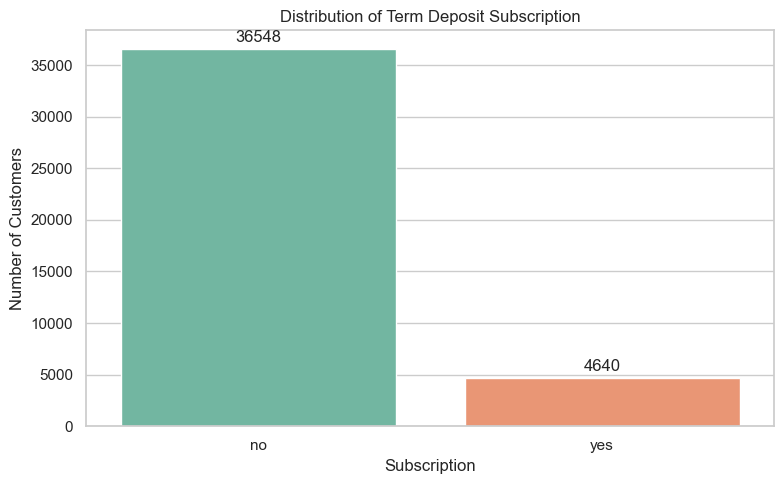

In [12]:
# TARGET VARIABLE DISTRIBUTION

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="y",
    hue="y",
    order=["no", "yes"],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Term Deposit Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()


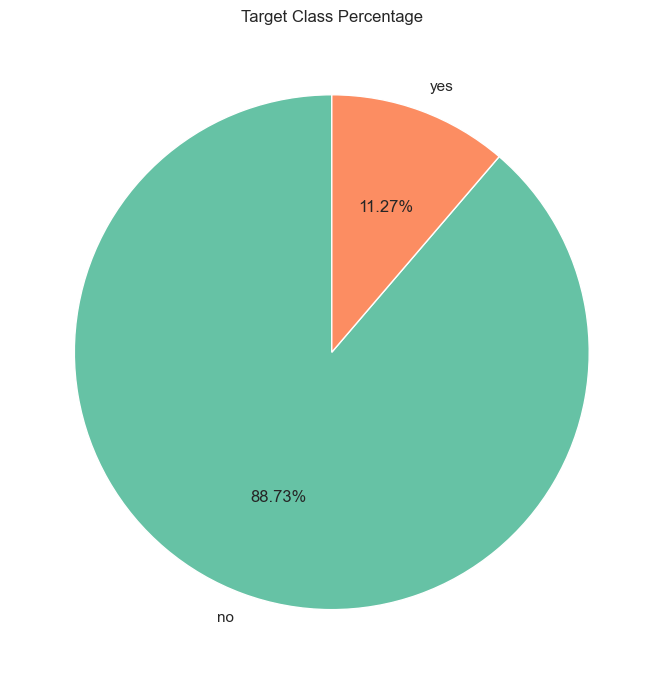

In [13]:
# TARGET VARIABLE PERCENTAGE

target_percentage = (
    df["y"].value_counts(normalize=True) * 100
)

plt.figure(figsize=(7, 7))

plt.pie(
    target_percentage,
    labels=target_percentage.index,
    autopct="%1.2f%%",
    startangle=90,
    colors=sns.color_palette("Set2")
)

plt.title("Target Class Percentage")
plt.tight_layout()
plt.show()


The target variable is imbalanced: 88.73% of observations belong to the `no` class, while 11.27% belong to the `yes` class. The majority-to-minority class ratio is approximately 7.88:1.

This imbalance means that a model can achieve high accuracy while still failing to identify a substantial proportion of actual subscribers. Model selection will therefore prioritize PR-AUC, while final business evaluation will emphasize Precision@K, Recall@K, and Lift@K.


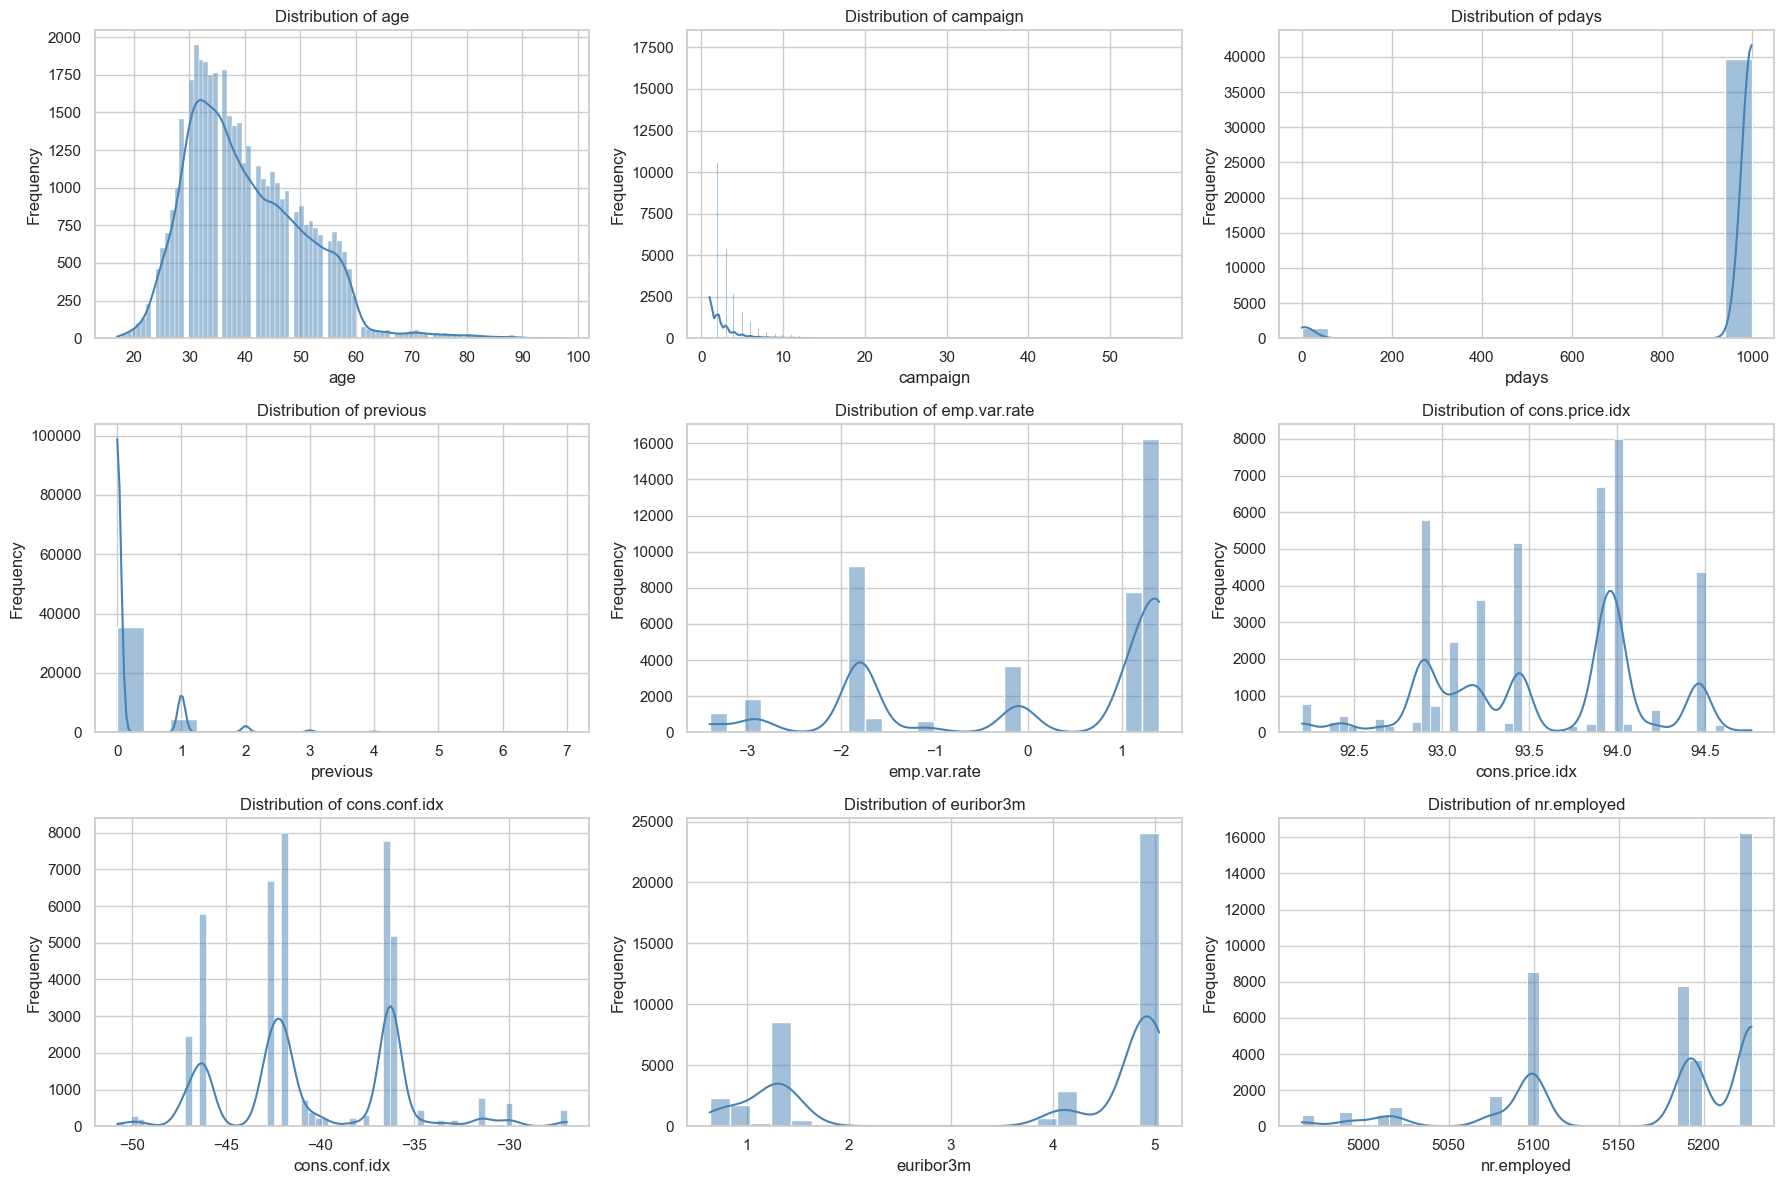

In [14]:
# NUMERICAL FEATURES DISTRIBUTION

numerical_features = [
    col for col in num_cols
    if col != "duration"
]

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(18, 12)
)

axes = axes.flatten()

for i, col in enumerate(numerical_features):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

The numerical feature distributions reveal different patterns across the dataset.

The `age` variable is concentrated mainly between 30 and 50 years, while `campaign` and `previous` exhibit highly right-skewed distributions.

The `pdays` variable is dominated by the value 999, which indicates that the customer was not previously contacted. This value represents a special indicator rather than an actual number of days.

The economic indicators (`emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, and `nr.employed`) show several concentrated values, suggesting that their distributions are not uniformly continuous.

These distribution characteristics will be considered during feature engineering, preprocessing, and model development.

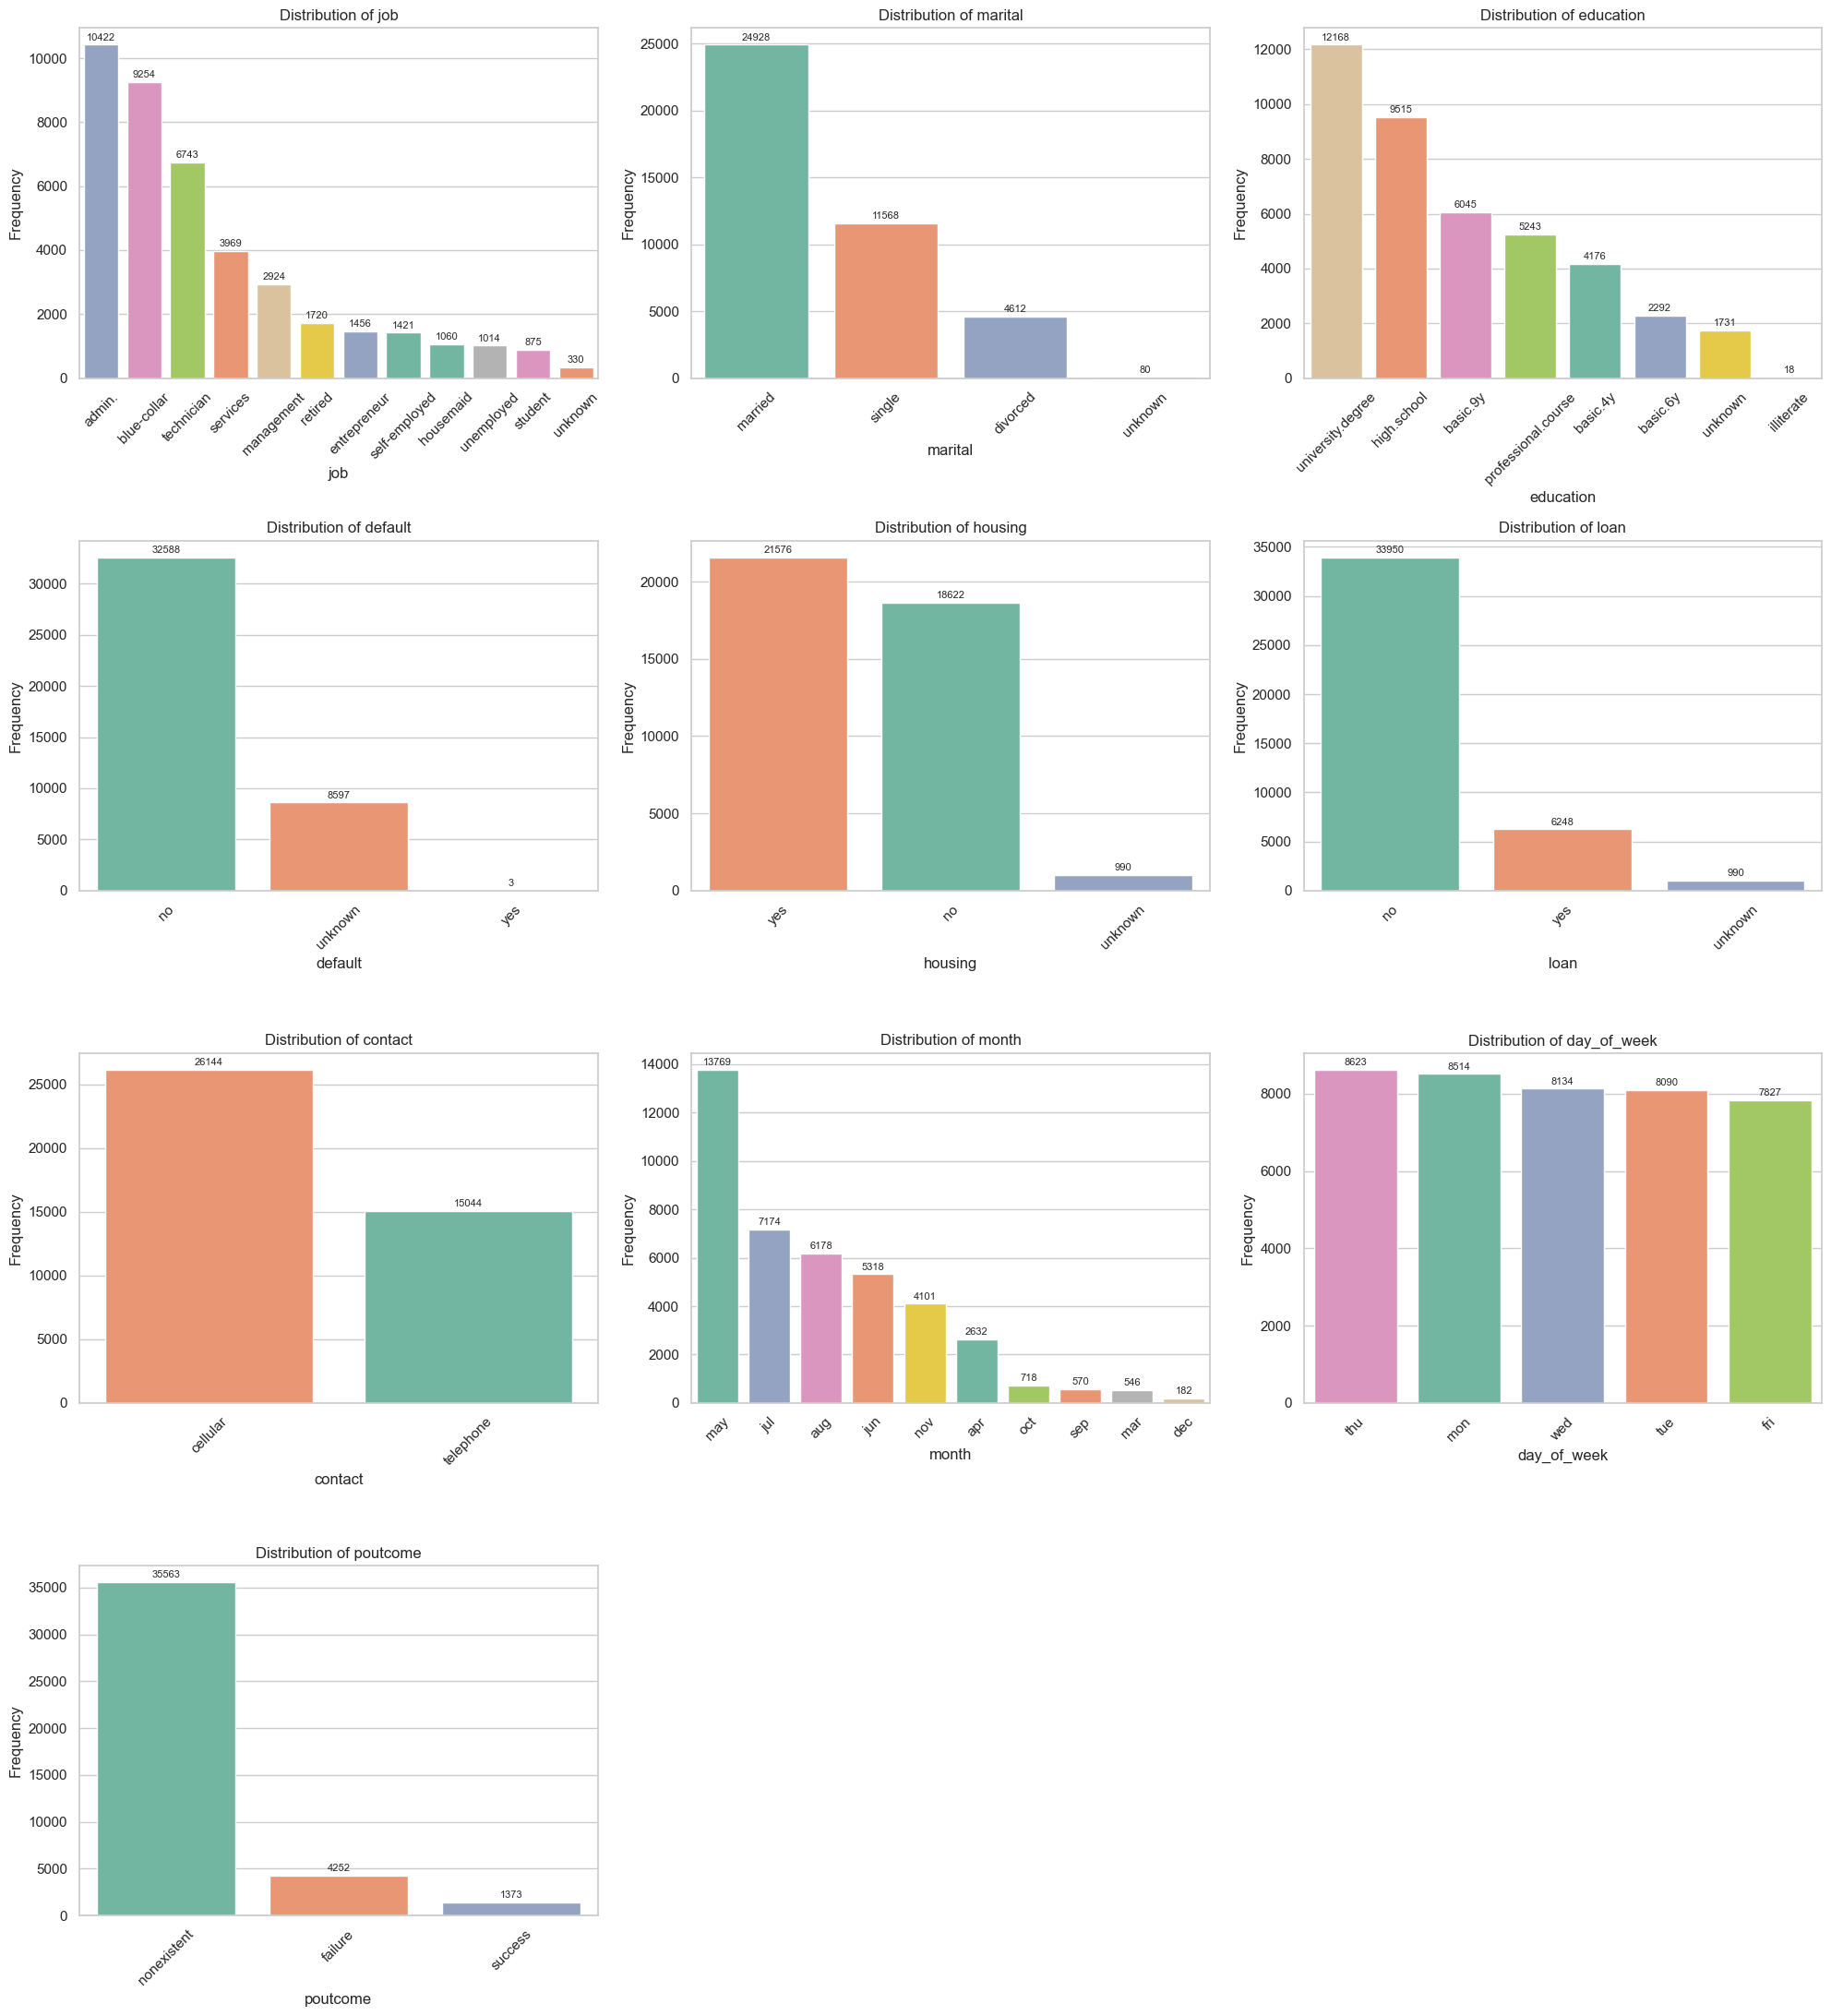

In [15]:
# CATEGORICAL FEATURES DISTRIBUTION

categorical_features = [
    col for col in cat_cols
    if col != "y"
]

fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(20, 22)
)

axes = axes.flatten()

for i, col in enumerate(categorical_features):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        hue=col,
        order=order,
        ax=axes[i],
        palette="Set2",
        legend=False
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")
    axes[i].tick_params(axis="x", rotation=45)

    for container in axes[i].containers:
        axes[i].bar_label(
            container,
            fmt="%.0f",
            padding=2,
            fontsize=8
        )

for j in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

The categorical feature distributions reveal differences in customer characteristics and marketing campaign activities.

The `job` feature is dominated by admin., blue-collar, and technician occupations. Most customers are married, while university.degree is the most frequent education category.

For financial-related attributes, most customers have no credit in default and no personal loan. However, the `default` feature contains a substantial number of unknown values.

The marketing campaign characteristics show that cellular contact is more frequently used than telephone contact. May is the month with the highest number of contacts, while the distribution across weekdays is relatively balanced.

The `poutcome` feature is dominated by the nonexistent category, indicating that most customers do not have a recorded outcome from a previous marketing campaign.

These patterns provide an initial understanding of customer characteristics and campaign activities. Further analysis is required to examine how these features relate to term deposit subscription.

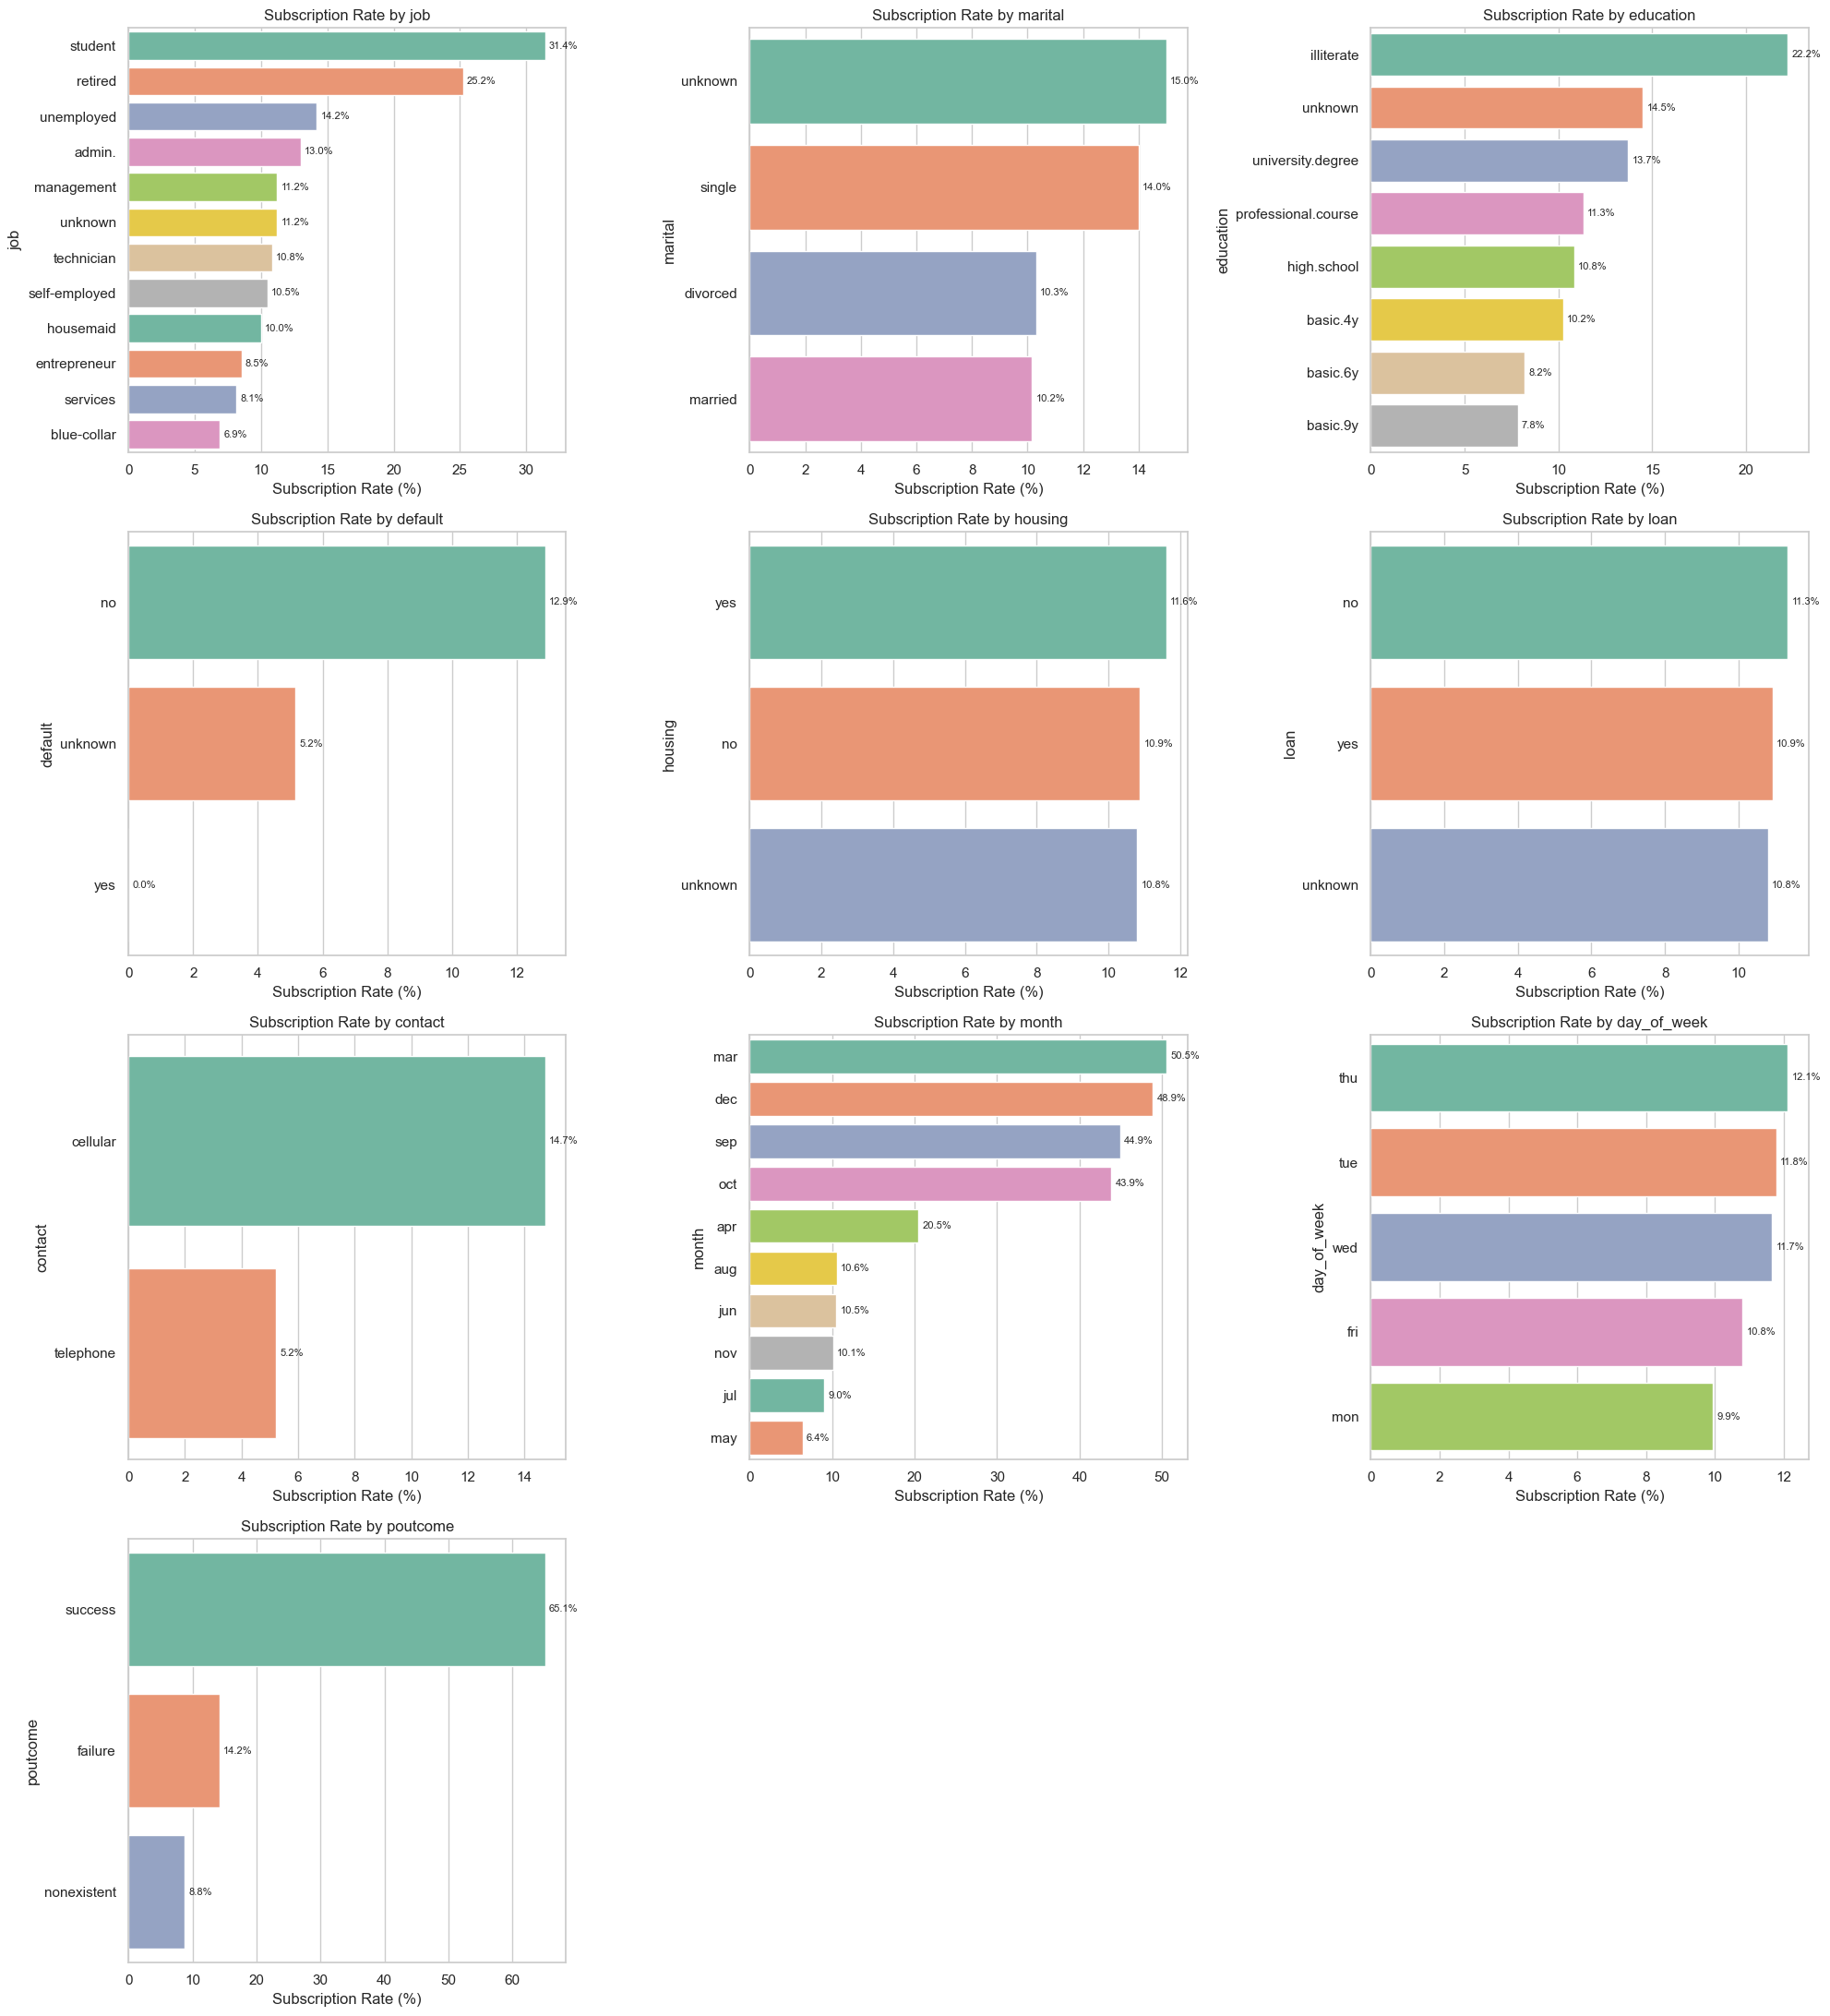

In [16]:
# CATEGORICAL FEATURES VS TARGET

fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(20, 22)
)

axes = axes.flatten()

for i, col in enumerate(categorical_features):

    subscription_rate = (
        df.groupby(col, observed=False)["y"]
        .apply(lambda x: (x == "yes").mean() * 100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=subscription_rate.values,
        y=subscription_rate.index,
        ax=axes[i],
        hue=subscription_rate.index,
        palette="Set2",
        legend=False
    )

    axes[i].set_title(f"Subscription Rate by {col}")
    axes[i].set_xlabel("Subscription Rate (%)")
    axes[i].set_ylabel(col)

    for container in axes[i].containers:
        axes[i].bar_label(
            container,
            fmt="%.1f%%",
            padding=3,
            fontsize=8
        )

for j in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

The bivariate analysis reveals differences in term deposit subscription rates across categorical features.

The `job` feature shows that students and retired customers have relatively high subscription rates, while blue-collar customers have the lowest rate.

For customer characteristics, single customers have a higher subscription rate than married and divorced customers. The education categories also show varying subscription rates, although some categories contain very few observations.

Regarding campaign characteristics, customers contacted through cellular have a higher subscription rate than those contacted through telephone. The subscription rate also varies considerably across months, with March, December, September, and October showing relatively high rates.

The `poutcome` feature shows the most notable difference, as customers with a previous successful campaign outcome have a substantially higher subscription rate.

These findings represent associations between categorical features and the target variable. Categories with small sample sizes should be interpreted cautiously.

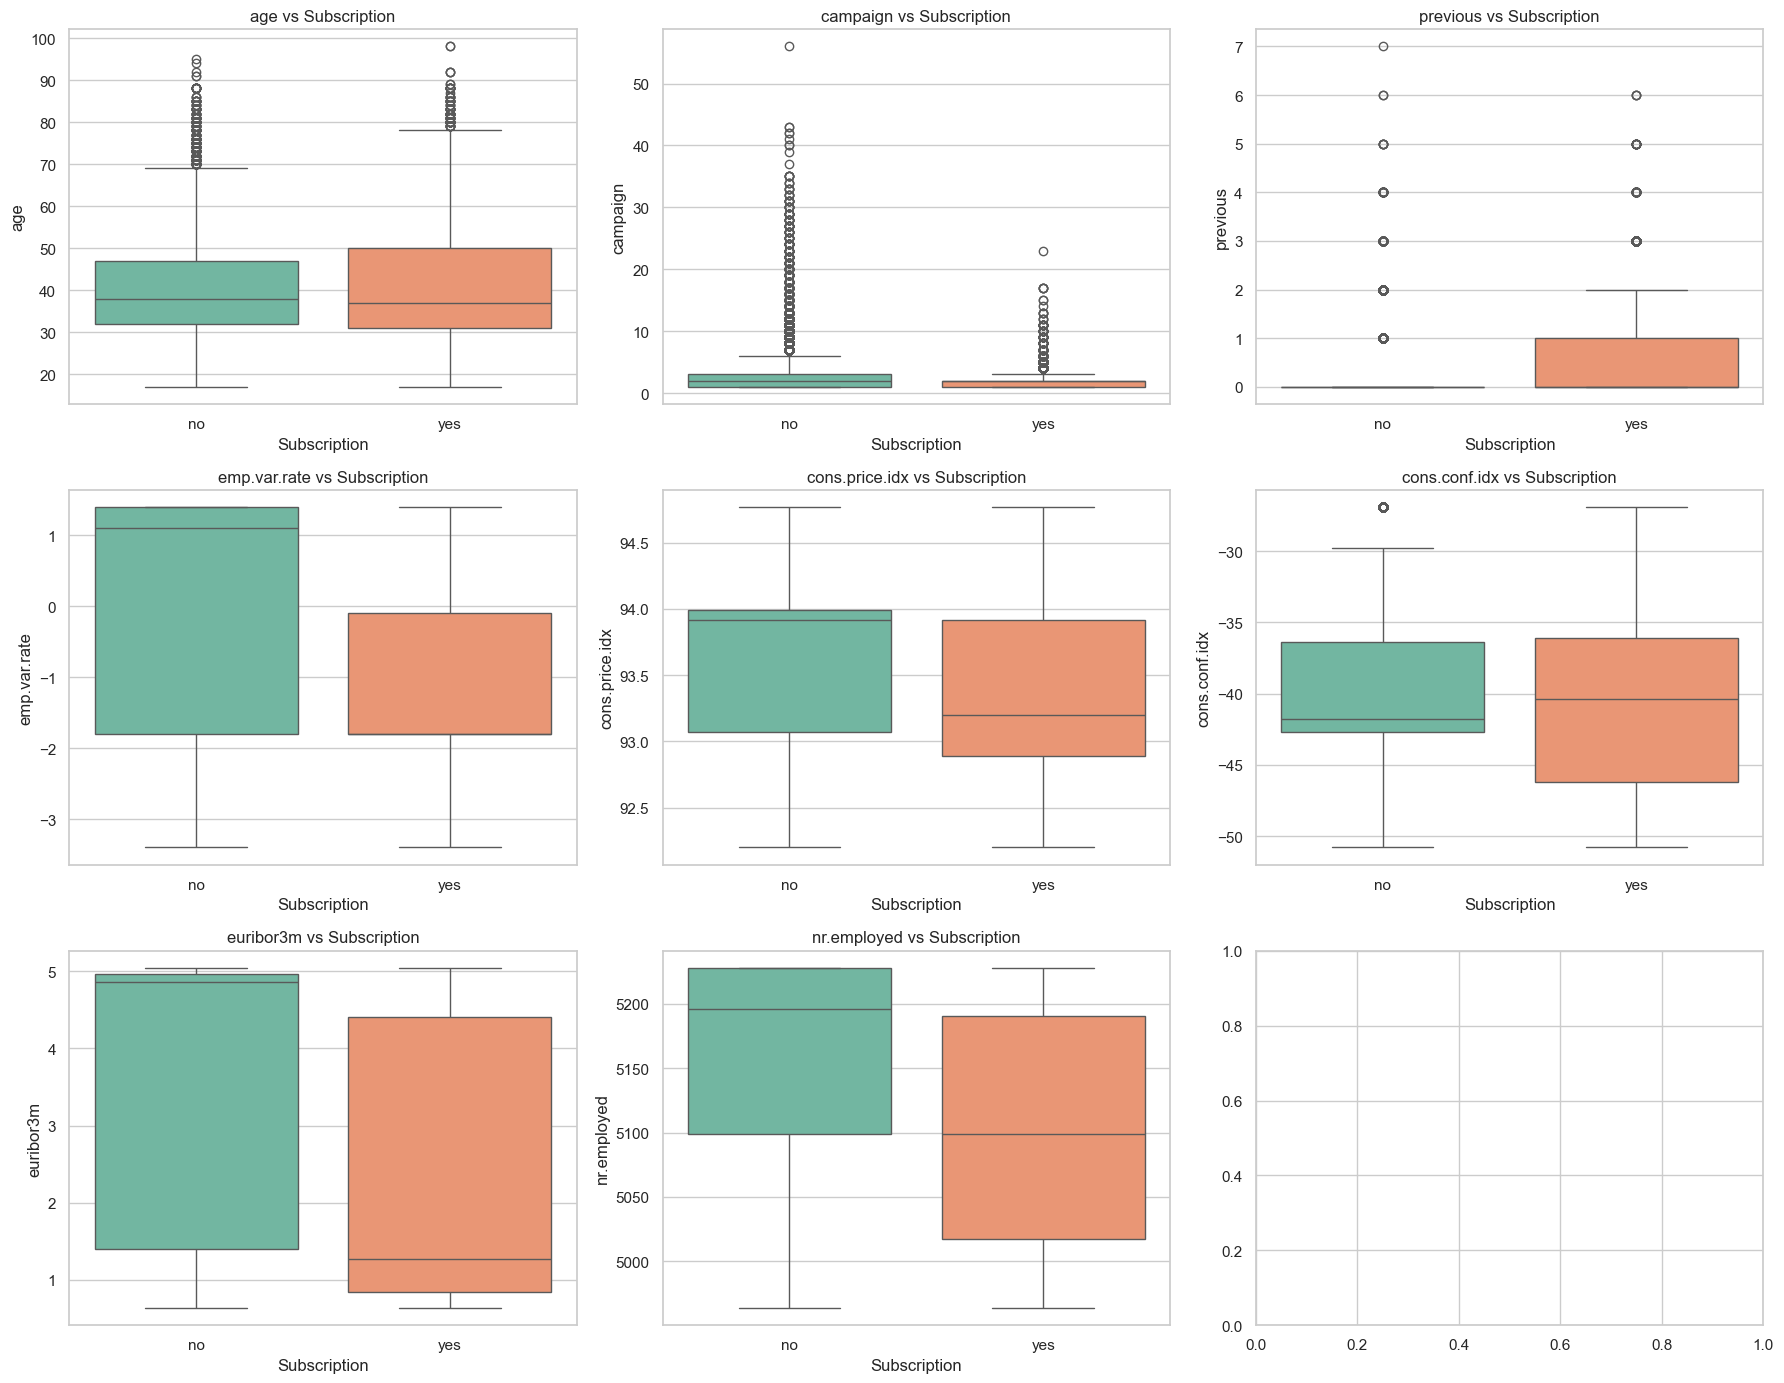

In [17]:
# NUMERICAL FEATURES VS TARGET

numerical_features = [
    col for col in num_cols
    if col not in ["duration", "pdays"]
]

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(18, 14)
)

axes = axes.flatten()

for i, col in enumerate(numerical_features):
    sns.boxplot(
        data=df,
        x="y",
        y=col,
        hue="y",
        order=["no", "yes"],
        ax=axes[i],
        palette="Set2",
        legend=False
    )

    axes[i].set_title(f"{col} vs Subscription")
    axes[i].set_xlabel("Subscription")
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

The numerical features show different distribution patterns between customers who subscribed and those who did not.

The `age` distributions are relatively similar across both target classes, indicating limited separation based on age alone.

The `campaign` feature suggests that customers with fewer campaign contacts tend to have a higher subscription rate. The `previous` feature also shows some differences in distribution, although most observations in both groups have a value of zero.

The economic indicators show more noticeable differences. Customers who subscribed tend to have lower values of `emp.var.rate`, `cons.price.idx`, `euribor3m`, and `nr.employed`, while `cons.conf.idx` has a slightly higher median.

These observations suggest that economic conditions and campaign-related variables may provide useful information for predicting term deposit subscription. However, these patterns represent associations and require further statistical and predictive evaluation.

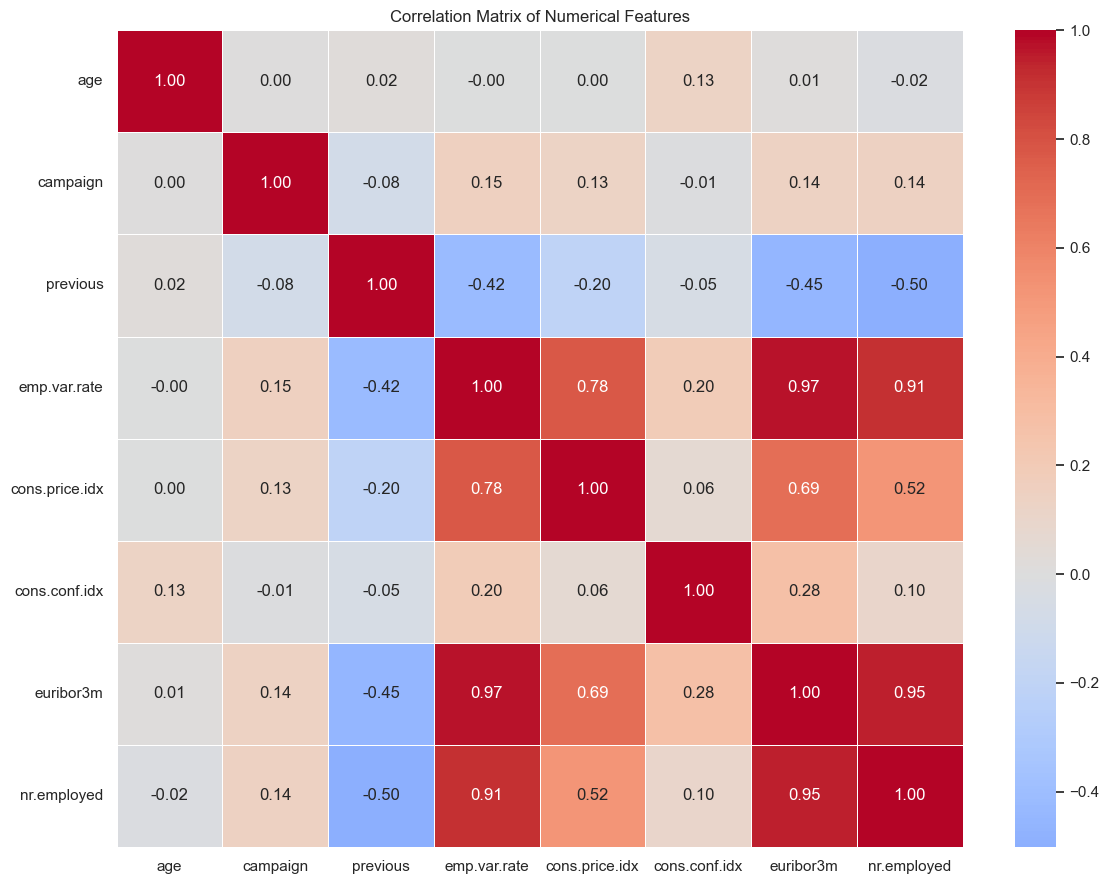

In [18]:
# CORRELATION ANALYSIS

correlation_features = [
    col for col in num_cols
    if col not in ["duration", "pdays"]
]

correlation_matrix = df[correlation_features].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

The correlation analysis reveals strong relationships among several numerical features.

The strongest positive correlations are observed between `emp.var.rate` and `euribor3m` (0.97), `euribor3m` and `nr.employed` (0.95), and `emp.var.rate` and `nr.employed` (0.91).

A strong positive correlation is also observed between `emp.var.rate` and `cons.price.idx` (0.78).

These findings indicate potential multicollinearity among the economic indicators. This issue may affect linear models, such as Logistic Regression, and should be considered during feature selection and model development.

In contrast, `age` and `campaign` generally show weak linear correlations with the other numerical features.

Overall, the correlation analysis provides useful information for understanding feature relationships and guiding subsequent preprocessing and modeling decisions.

In [19]:
# PDAYS SPECIAL VALUE ANALYSIS

pdays_distribution = (
    df["pdays"]
    .value_counts()
    .sort_index()
    .reset_index()
)

pdays_distribution.columns = ["pdays", "count"]

pdays_distribution["percentage"] = (
    pdays_distribution["count"] / len(df) * 100
)

display(pdays_distribution)

,pdays,count,percentage
0,0,15,0.036
1,1,26,0.063
2,2,61,0.148
3,3,439,1.066
4,4,118,0.286
5,5,46,0.112
6,6,412,1.000
7,7,60,0.146
8,8,18,0.044
9,9,64,0.155


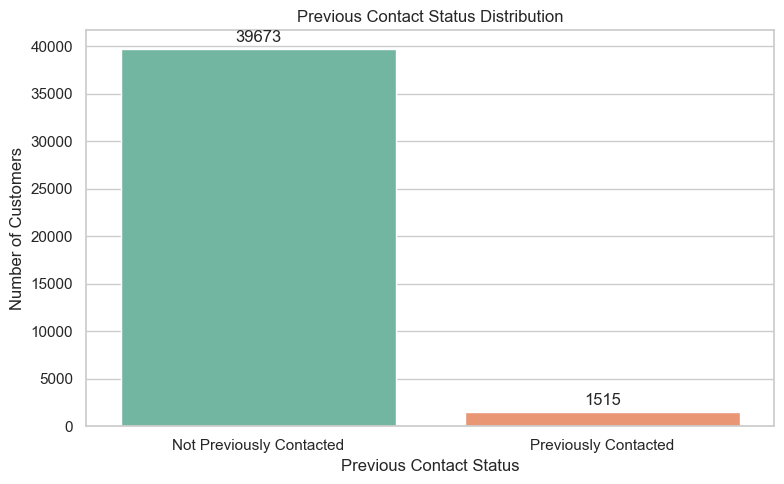

In [20]:
# PDAYS CONTACT HISTORY DISTRIBUTION

pdays_status = df["pdays"].apply(
    lambda x: "Not Previously Contacted" if x == 999
    else "Previously Contacted"
)

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=pdays_status,
    hue=pdays_status,
    order=[
        "Not Previously Contacted",
        "Previously Contacted"
    ],
    palette="Set2",
    legend=False
)

plt.title("Previous Contact Status Distribution")
plt.xlabel("Previous Contact Status")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

### **Special Value Analysis**

The `pdays` feature contains a special value of 999, indicating that a customer was not previously contacted during an earlier marketing campaign.

The analysis shows that 39,673 observations (96.32%) have a value of 999, while only 1,515 observations (3.68%) represent customers who were previously contacted.

This indicates that the `pdays` feature is highly dominated by the special value.

To preserve the information contained in this feature, it will be transformed into two separate features during feature engineering:

- `previously_contacted`: Indicates whether a customer was previously contacted.
- `days_since_previous_contact`: Represents the number of days since the previous contact, with unavailable values represented as missing values.

This transformation separates previous contact status from the actual number of days since contact.

In [21]:
# PDAYS FEATURE ENGINEERING

df["previously_contacted"] = (
    df["pdays"] != 999
).astype(int)

df["days_since_previous_contact"] = (
    df["pdays"].replace(999, np.nan)
)

# Verify engineered features
display(
    df[
        [
            "pdays",
            "previously_contacted",
            "days_since_previous_contact"
        ]
    ].head(10)
)

# Check feature distribution
display(
    df[
        [
            "previously_contacted",
            "days_since_previous_contact"
        ]
    ].describe().T
)

# Check missing values in engineered feature
print(
    "Missing values in days_since_previous_contact:",
    df["days_since_previous_contact"].isnull().sum()
)

,pdays,previously_contacted,days_since_previous_contact
0,999,0,NaN
1,999,0,NaN
2,999,0,NaN
3,999,0,NaN
4,999,0,NaN
5,999,0,NaN
6,999,0,NaN
7,999,0,NaN
8,999,0,NaN
9,999,0,NaN


,count,mean,std,min,25%,50%,75%,max
previously_contacted,"41,188.000",0.037,0.188,0.000,0.000,0.000,0.000,1.000
days_since_previous_contact,"1,515.000",6.015,3.825,0.000,3.000,6.000,7.000,27.000


Missing values in days_since_previous_contact: 39673


### **Feature Engineering**

The `pdays` feature was transformed to handle its special value of 999, which indicates that a customer was not previously contacted.

Two new features were created:

- `previously_contacted`: A binary feature indicating whether a customer was previously contacted.
- `days_since_previous_contact`: Represents the number of days since the previous contact.

The `previously_contacted` feature shows that only 3.68% of customers had been contacted previously.

The `days_since_previous_contact` feature contains 1,515 valid observations, with a mean of approximately 6.02 days and a median of 6 days.

The remaining 39,673 observations are represented as NaN because these customers have no previous contact history. These values are intentional and will be handled appropriately during the preprocessing stage.

In [22]:
# FEATURE ENGINEERING VALIDATION

print("Dataset shape:", df.shape)

print("\nPreviously Contacted Distribution:")
display(
    df["previously_contacted"].value_counts()
)

print("\nFeature Consistency Check:")

check_consistency = (
    (df["pdays"] == 999) ==
    (df["previously_contacted"] == 0)
)

print(
    "All records are consistent:",
    check_consistency.all()
)

print(
    "Previously contacted records:",
    (df["previously_contacted"] == 1).sum()
)

print(
    "Valid days since previous contact:",
    df["days_since_previous_contact"].notna().sum()
)

Dataset shape: (41188, 23)

Previously Contacted Distribution:


previously_contacted
0    39673
1     1515
Name: count, dtype: int64


Feature Consistency Check:
All records are consistent: True
Previously contacted records: 1515
Valid days since previous contact: 1515


The feature engineering validation confirms that the transformation was performed correctly.

The dataset retains all 41,188 observations, while the number of features increases from 21 to 23.

The consistency check confirms that all records are correctly classified based on the original `pdays` values. Furthermore, the number of valid observations in `days_since_previous_contact` matches the number of previously contacted customers.

Therefore, the engineered features are consistent with the original data and can be retained for subsequent preprocessing.

In [23]:
# OUTLIER DETECTION USING IQR

outlier_features = [
    "age",
    "campaign",
    "previous",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

outlier_summary = []

for col in outlier_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_percentage = (
        outlier_count / len(df) * 100
    )

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage": outlier_percentage
    })

outlier_df = pd.DataFrame(outlier_summary)

display(
    outlier_df.round(3)
)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,9.500,69.500,469,1.139
1,campaign,-2.000,6.000,2406,5.842
2,previous,0.000,0.000,5625,13.657
3,emp.var.rate,-6.600,6.200,0,0.000
4,cons.price.idx,91.697,95.372,0,0.000
5,cons.conf.idx,-52.150,-26.950,447,1.085
6,euribor3m,-4.081,10.386,0,0.000
7,nr.employed,"4,905.600","5,421.600",0,0.000


### **Outlier Analysis**

Outlier detection was performed using the Interquartile Range (IQR) method to identify extreme observations in numerical features.

The results show that `previous` has the highest outlier percentage (13.657%), followed by `campaign` (5.842%), `age` (1.139%), and `cons.conf.idx` (1.085%).

The high outlier percentage in `previous` is mainly caused by its zero-inflated distribution, where both the first and third quartiles are zero. Consequently, all positive values are classified as outliers by the IQR method.

The outliers in `campaign` may represent customers who received a relatively high number of marketing contacts. These observations may contain meaningful business information rather than data errors.

No outliers were detected in `emp.var.rate`, `cons.price.idx`, `euribor3m`, and `nr.employed` based on the IQR method.

Therefore, all observations will be retained at this stage. No automatic outlier removal or capping will be applied, as extreme values may contain useful information for predictive modeling.

### **Final Feature Selection**

Based on the exploratory data analysis and feature engineering results, 20 predictor features were selected for model development.

The selected features consist of 10 numerical features and 10 categorical features.

**Numerical Features**

The numerical features include customer demographics, campaign-related information, and economic indicators. Two engineered features, `previously_contacted` and `days_since_previous_contact`, are also included to preserve the information from the original `pdays` variable.

**Categorical Features**

The categorical features represent customer characteristics and marketing campaign information. The `unknown` values are retained as separate categories rather than being treated as missing values.

**Excluded Features**

The `duration` feature is excluded because it is only known after a marketing call has taken place. Including this feature would introduce target leakage in the intended prediction scenario, where subscription is predicted before the call.

The original `pdays` feature is also excluded because its information has been represented through the two engineered features.

The target variable is `y`, which indicates whether a customer subscribed to a term deposit.

The selected features will be used in the subsequent preprocessing and model development stages.

In [24]:
# FINAL FEATURE SELECTION

numerical_features = [
    "age",
    "campaign",
    "previous",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed",
    "previously_contacted",
    "days_since_previous_contact"
]

categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "poutcome"
]

target = "y"

# Define predictor variables and target
selected_features = numerical_features + categorical_features

X = df[selected_features].copy()
y = df[target].copy()

# Display feature information
print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))
print("Total Predictor Features:", len(selected_features))

print("\nFeature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
display(y.value_counts())

Numerical Features: 10
Categorical Features: 10
Total Predictor Features: 20

Feature Matrix Shape: (41188, 20)
Target Shape: (41188,)

Target Distribution:


y
no     36548
yes     4640
Name: count, dtype: int64

In [25]:
# TRAIN-TEST SPLIT

from sklearn.model_selection import train_test_split

RANDOM_STATE = 610

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Display dataset dimensions
print("Training Set Shape:", X_train.shape)
print("Testing Set Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Set Shape: (32950, 20)
Testing Set Shape: (8238, 20)

Training Target Shape: (32950,)
Testing Target Shape: (8238,)


### **Data Preprocessing Strategy**

Data preprocessing prepares the selected numerical and categorical variables for machine learning. Separate pipelines are used so that each feature type receives an appropriate transformation.

**Numerical Features**

Numerical features are processed using Median Imputation and Robust Scaling.

- **Median Imputation:** Replaces missing numerical values using the median. This is relevant to `days_since_previous_contact`, where missing values intentionally indicate no previous contact history.
- **Robust Scaling:** Uses the median and interquartile range (IQR), making the transformation less sensitive to skewed distributions and extreme observations identified during exploratory analysis.

**Categorical Features**

Categorical features are processed using Most Frequent Imputation and One-Hot Encoding.

- **Most Frequent Imputation:** Handles any missing categorical values while preserving valid category representations.
- **One-Hot Encoding:** Converts nominal categories into binary indicator features without imposing an artificial order. The `handle_unknown="ignore"` setting allows the pipeline to handle categories not observed during fitting.

**Pipeline Integration**

The numerical and categorical pipelines are combined using `ColumnTransformer`. The complete preprocessor is placed inside each machine learning pipeline so that it is fitted only on the training portion of each cross-validation fold.

For the final model, the preprocessing pipeline is fitted on the complete training set and then applied to the untouched test set. This prevents information from the test set from influencing preprocessing parameters.


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

# NUMERICAL PREPROCESSING PIPELINE
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler())
    ]
)

### **Categorical Preprocessing Pipeline**

Categorical features are processed using Most Frequent Imputation followed by One-Hot Encoding. The imputer handles any missing categorical values, while the encoder converts nominal categories into binary numerical features.

The `handle_unknown="ignore"` parameter prevents errors if a category appears in validation or test data but was not observed during fitting.

### **Combining Preprocessing Pipelines**

The numerical pipeline applies median imputation followed by Robust Scaling. The categorical pipeline applies most frequent imputation followed by One-Hot Encoding.

Both pipelines are combined using `ColumnTransformer`. This integrated structure applies the correct transformation to each feature group and can be embedded directly in machine learning pipelines to reduce data leakage.


In [27]:
# CATEGORICAL PREPROCESSING PIPELINE

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [28]:
# COMBINE PREPROCESSING PIPELINES

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [29]:
# FIT AND TRANSFORM TRAINING DATA

X_train_processed = preprocessor.fit_transform(X_train)

print("Processed Training Data Shape:", X_train_processed.shape)

Processed Training Data Shape: (32950, 63)


In [30]:
# TRANSFORM TESTING DATA

X_test_processed = preprocessor.transform(X_test)

print("Processed Testing Data Shape:", X_test_processed.shape)

Processed Testing Data Shape: (8238, 63)


### **III. Modeling**

#### **Machine Learning Model Selection**

Two baseline algorithms are evaluated: Logistic Regression and Random Forest. Both use `class_weight="balanced"` to account for the imbalanced target distribution.

A 5-Fold Stratified Cross-Validation strategy is used to preserve the target class proportions across folds. **PR-AUC (Average Precision) is the primary model selection metric**, while ROC-AUC is retained as a supporting metric. Training PR-AUC and the standard deviation of CV PR-AUC are also reviewed to assess possible overfitting and fold-to-fold variability.

Each algorithm is wrapped in a pipeline containing the preprocessing steps. This ensures that imputation, scaling, and encoding are fitted independently within each training fold.

After comparing the candidate models, the model with the highest mean CV PR-AUC is selected. OOF probabilities from the training set are then used to determine the F1-based classification threshold. The selected model is refitted on the full training set before the final test evaluation.


In [31]:
# MODEL SELECTION LIBRARIES
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [32]:

# STRATIFIED CROSS-VALIDATION


POSITIVE_CLASS = "yes"
TOP_K_FRACTION = 0.20

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# CROSS-VALIDATION SCORING FUNCTIONS
def get_positive_probabilities(estimator, X):
    positive_idx = list(estimator.classes_).index(POSITIVE_CLASS)
    return estimator.predict_proba(X)[:, positive_idx]


def pr_auc_scorer(estimator, X, y):
    y_binary = (np.asarray(y) == POSITIVE_CLASS).astype(int)
    probabilities = get_positive_probabilities(estimator, X)
    return average_precision_score(y_binary, probabilities)


def precision_at_k_scorer(estimator, X, y):
    y_binary = (np.asarray(y) == POSITIVE_CLASS).astype(int)
    probabilities = get_positive_probabilities(estimator, X)

    k = max(1, int(np.ceil(TOP_K_FRACTION * len(y_binary))))
    top_k_indices = np.argsort(probabilities)[-k:]

    return y_binary[top_k_indices].mean()


def recall_at_k_scorer(estimator, X, y):
    y_binary = (np.asarray(y) == POSITIVE_CLASS).astype(int)
    probabilities = get_positive_probabilities(estimator, X)

    k = max(1, int(np.ceil(TOP_K_FRACTION * len(y_binary))))
    top_k_indices = np.argsort(probabilities)[-k:]

    return (
        y_binary[top_k_indices].sum()
        / max(y_binary.sum(), 1)
    )


def roc_auc_scorer(estimator, X, y):
    y_binary = (np.asarray(y) == POSITIVE_CLASS).astype(int)
    probabilities = get_positive_probabilities(estimator, X)
    return roc_auc_score(y_binary, probabilities)


scoring = {
    "pr_auc": pr_auc_scorer,
    "precision_at_k": precision_at_k_scorer,
    "recall_at_k": recall_at_k_scorer,
    "roc_auc": roc_auc_scorer
}


In [33]:
# MACHINE LEARNING MODELS
ml_models = {
    "Logistic Regression": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=RANDOM_STATE
            ))
        ]
    ),

    "Random Forest": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", RandomForestClassifier(
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=1
            ))
        ]
    )
}

In [34]:
# MACHINE LEARNING MODEL EVALUATION
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_recall_curve, precision_score,
    recall_score, f1_score
)

POSITIVE_CLASS = "yes"
TOP_K = 100  # Bank marketing outreach capacity

# CROSS-VALIDATION SCORING FUNCTIONS
def get_positive_probabilities(estimator, X):
    positive_idx = list(estimator.classes_).index(POSITIVE_CLASS)
    return estimator.predict_proba(X)[:, positive_idx]


def pr_auc_scorer(estimator, X, y):
    y_binary = (np.asarray(y) == POSITIVE_CLASS).astype(int)
    probabilities = get_positive_probabilities(estimator, X)
    return average_precision_score(y_binary, probabilities)


def precision_at_k_scorer(estimator, X, y):
    y_binary = (np.asarray(y) == POSITIVE_CLASS).astype(int)
    probabilities = get_positive_probabilities(estimator, X)
    k = min(TOP_K, len(y_binary))
    top_k = np.argsort(probabilities)[-k:]
    return y_binary[top_k].mean()


def recall_at_k_scorer(estimator, X, y):
    y_binary = (np.asarray(y) == POSITIVE_CLASS).astype(int)
    probabilities = get_positive_probabilities(estimator, X)
    k = min(TOP_K, len(y_binary))
    top_k = np.argsort(probabilities)[-k:]
    return y_binary[top_k].sum() / max(y_binary.sum(), 1)


def lift_at_k_scorer(estimator, X, y):
    y_binary = (np.asarray(y) == POSITIVE_CLASS).astype(int)
    probabilities = get_positive_probabilities(estimator, X)
    k = min(TOP_K, len(y_binary))
    top_k = np.argsort(probabilities)[-k:]
    precision_at_k = y_binary[top_k].mean()
    overall_rate = y_binary.mean()
    return precision_at_k / overall_rate if overall_rate > 0 else 0.0


def roc_auc_scorer(estimator, X, y):
    y_binary = (np.asarray(y) == POSITIVE_CLASS).astype(int)
    probabilities = get_positive_probabilities(estimator, X)
    return roc_auc_score(y_binary, probabilities)


scoring = {
    "pr_auc": pr_auc_scorer,
    "precision_at_k": precision_at_k_scorer,
    "recall_at_k": recall_at_k_scorer,
    "lift_at_k": lift_at_k_scorer,
    "roc_auc": roc_auc_scorer
}



In [35]:
# CROSS-VALIDATION MODEL EVALUATION
cv_results = []

for model_name, model in ml_models.items():
    scores = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv_strategy,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=True
    )

    cv_results.append({
        "Model": model_name,
        "Train PR-AUC": scores["train_pr_auc"].mean(),
        "CV PR-AUC": scores["test_pr_auc"].mean(),
        "CV PR-AUC Std": scores["test_pr_auc"].std(),
        "CV Precision@K": scores["test_precision_at_k"].mean(),
        "CV Recall@K": scores["test_recall_at_k"].mean(),
        "CV Lift@K": scores["test_lift_at_k"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

ml_cv_results = pd.DataFrame(cv_results)

ml_cv_results = ml_cv_results.sort_values(
    by="CV PR-AUC",
    ascending=False
).reset_index(drop=True)

display(ml_cv_results)

# MODEL SELECTION BASED ON CV PR-AUC
best_cv_model_name = ml_cv_results.loc[0, "Model"]

print("Best Model based on CV PR-AUC:", best_cv_model_name)

,Model,Train PR-AUC,CV PR-AUC,CV PR-AUC Std,CV Precision@K,CV Recall@K,CV Lift@K,CV ROC-AUC
0,Logistic Regression,0.449,0.444,0.013,0.742,0.100,6.587,0.792
1,Random Forest,0.999,0.372,0.012,0.554,0.075,4.918,0.775


Best Model based on CV PR-AUC: Logistic Regression


In [36]:
# OOF PREDICTIONS AND THRESHOLD OPTIMIZATION
oof_thresholds = {}
fitted_ml_models = {}

y_train_binary = (np.asarray(y_train) == POSITIVE_CLASS).astype(int)
class_labels = np.unique(np.asarray(y_train))
positive_idx = list(class_labels).index(POSITIVE_CLASS)

for model_name, model in ml_models.items():
    oof_probabilities = cross_val_predict(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv_strategy,
        method="predict_proba",
        n_jobs=-1
    )[:, positive_idx]

    precision, recall, thresholds = precision_recall_curve(
        y_train_binary,
        oof_probabilities
    )

    oof_f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_threshold_idx = np.argmax(oof_f1_scores)
    optimal_threshold = thresholds[best_threshold_idx]

    oof_thresholds[model_name] = optimal_threshold

    # REFIT MODEL USING FULL TRAINING DATA
    model.fit(X_train, y_train)
    fitted_ml_models[model_name] = model

    print(
        f"{model_name} | "
        f"OOF Threshold: {optimal_threshold:.4f} | "
        f"OOF F1: {oof_f1_scores[best_threshold_idx]:.4f}"
    )



Logistic Regression | OOF Threshold: 0.6679 | OOF F1: 0.4857
Random Forest | OOF Threshold: 0.4600 | OOF F1: 0.4562


In [37]:
# MACHINE LEARNING TEST SET EVALUATION
y_test_binary = (np.asarray(y_test) == POSITIVE_CLASS).astype(int)

test_results = []

for model_name, model in fitted_ml_models.items():
    # TEST PROBABILITIES
    positive_idx = list(model.classes_).index(POSITIVE_CLASS)
    y_test_probabilities = model.predict_proba(X_test)[:, positive_idx]

    # APPLY OOF-BASED DECISION THRESHOLD
    optimal_threshold = oof_thresholds[model_name]
    negative_class = next(
        label for label in model.classes_
        if label != POSITIVE_CLASS
    )

    y_test_predictions = np.where(
        y_test_probabilities >= optimal_threshold,
        POSITIVE_CLASS,
        negative_class
    )

    # PRECISION@K, RECALL@K, AND LIFT@K
    k = min(TOP_K, len(y_test_binary))
    top_k_indices = np.argsort(y_test_probabilities)[-k:]
    top_k_targets = y_test_binary[top_k_indices]

    precision_at_k = top_k_targets.mean()
    recall_at_k = (
        top_k_targets.sum() / max(y_test_binary.sum(), 1)
    )

    overall_subscription_rate = y_test_binary.mean()
    lift_at_k = (
        precision_at_k / overall_subscription_rate
        if overall_subscription_rate > 0 else 0.0
    )

    # CLASSIFICATION METRICS
    test_precision = precision_score(
        y_test, y_test_predictions,
        pos_label=POSITIVE_CLASS,
        zero_division=0
    )

    test_recall = recall_score(
        y_test, y_test_predictions,
        pos_label=POSITIVE_CLASS,
        zero_division=0
    )

    test_f1 = f1_score(
        y_test, y_test_predictions,
        pos_label=POSITIVE_CLASS,
        zero_division=0
    )

    # ADDITIONAL DISCRIMINATION METRICS
    test_pr_auc = average_precision_score(
        y_test_binary, y_test_probabilities
    )

    test_roc_auc = roc_auc_score(
        y_test_binary, y_test_probabilities
    )

    # STORE TEST RESULTS
    test_results.append({
        "Model": model_name,
        "Threshold": optimal_threshold,
        "Precision@K": precision_at_k,
        "Recall@K": recall_at_k,
        "Lift@K": lift_at_k,
        "Precision": test_precision,
        "Recall": test_recall,
        "F1-Score": test_f1,
        "PR-AUC": test_pr_auc,
        "ROC-AUC": test_roc_auc
    })


# TEST SET PERFORMANCE COMPARISON
ml_test_results = pd.DataFrame(test_results)

ml_test_results = ml_test_results.sort_values(
    by="Precision@K",
    ascending=False
).reset_index(drop=True)

display(ml_test_results.round(4))


,Model,Threshold,Precision@K,Recall@K,Lift@K,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
0,Logistic Regression,0.668,0.750,0.081,6.658,0.436,0.545,0.485,0.457,0.798
1,Random Forest,0.460,0.510,0.055,4.527,0.418,0.529,0.467,0.377,0.776


In [38]:

# MLP CROSS-VALIDATION CONFIGURATION
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from scipy.sparse import issparse
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_recall_curve, precision_score,
    recall_score, f1_score
)
from torch.utils.data import TensorDataset, DataLoader

# TRAINING CONFIGURATION
BATCH_SIZE = 256
PATIENCE = 10
LEARNING_RATE = 0.001
POSITIVE_CLASS = "yes"
TOP_K = 100

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Computing device:", device)


PyTorch version: 2.15.0+cpu
Computing device: cpu


### **MLP Model Development**

#### **MLP Architecture**

A Multi-Layer Perceptron (MLP) is implemented as a binary classification model. The network contains an input layer, two hidden layers, and a single output neuron.

The input layer receives the numerical features generated by the fitted preprocessing pipeline. The first hidden layer contains 128 neurons and the second contains 64 neurons. ReLU activation functions introduce non-linearity, Batch Normalization supports more stable optimization, and Dropout is applied to reduce overfitting.

The output layer produces one logit. A sigmoid transformation is applied when probabilities are required; during training, `BCEWithLogitsLoss` combines the sigmoid operation and binary cross-entropy loss in a numerically stable implementation.

#### **MLP Training Configuration**

The MLP uses the Adam optimizer with a learning rate of 0.001 and a batch size of 256. Training is limited to a maximum of 50 epochs.

`BCEWithLogitsLoss` is used for binary classification. The positive class weight is calculated from the ratio of negative to positive observations in the MLP training subset to account for class imbalance.

#### **Training and Validation Strategy**

A stratified 80:20 split is created within the original training set. The internal validation subset is used only to monitor validation loss and apply Early Stopping. The preprocessing pipeline is fitted on the MLP training subset before transforming the validation and test subsets, preventing preprocessing leakage.

The original test set remains untouched until final evaluation. It is not used for early stopping, threshold selection, or training decisions.


In [39]:
# DEEP LEARNING LIBRARIES
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_recall_curve, precision_score,
    recall_score, f1_score
)
from scipy.sparse import issparse

# SET RANDOM SEED
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

# DEVICE CONFIGURATION
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Computing device:", device)

PyTorch version: 2.15.0+cpu
Computing device: cpu


In [40]:
# MLP EXPERIMENT CONFIGURATION
BATCH_SIZE = 256
EPOCHS = 100
PATIENCE = 10
LEARNING_RATE = 0.001
POSITIVE_CLASS = "yes"
TOP_K = 100

In [41]:
# TARGET CONVERSION
y_train_array = np.asarray(y_train)
y_test_array = np.asarray(y_test)

y_train_binary = (y_train_array == POSITIVE_CLASS).astype(int)
y_test_binary = (y_test_array == POSITIVE_CLASS).astype(int)

print("\nTraining samples:", len(y_train_array))
print("Testing samples:", len(y_test_array))
print("Positive class:", POSITIVE_CLASS)
print("Number of folds:", cv_strategy.n_splits)


Training samples: 32950
Testing samples: 8238
Positive class: yes
Number of folds: 5


In [42]:

# MLP MODEL ARCHITECTURE
def build_mlp(input_dim):
    return nn.Sequential(
        nn.Linear(input_dim, 128),
        nn.BatchNorm1d(128),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(128, 64),
        nn.BatchNorm1d(64),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(64, 1)
    ).to(device)

In [43]:
# DATA PREPARATION FUNCTIONS
def select_rows(data, indices):
    return data.iloc[indices] if hasattr(data, "iloc") else data[indices]


def to_dense_array(data):
    if issparse(data):
        data = data.toarray()
    return np.asarray(data, dtype=np.float32)

In [44]:
# CREATE DATA LOADERS
def create_loader(X, y, shuffle=False, seed=RANDOM_STATE):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )

    if len(dataset) < 2:
        raise ValueError("MLP training requires at least two samples.")

    drop_last = (
        shuffle
        and len(dataset) > BATCH_SIZE
        and len(dataset) % BATCH_SIZE == 1
    )

    generator = torch.Generator().manual_seed(seed)

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=generator if shuffle else None,
        drop_last=drop_last
    )


In [45]:
# REDEFINE POSITIVE CLASS WEIGHT
def get_pos_weight(y):
    positive_count = int(np.sum(y == 1))
    negative_count = len(y) - positive_count

    if positive_count == 0:
        raise ValueError("Positive class is missing in the training data.")

    return torch.tensor(
        negative_count / positive_count,
        dtype=torch.float32,
        device=device
    )


In [46]:
# MLP PREDICTION FUNCTION
def predict_mlp(model, X):
    model.eval()
    probabilities = []
    X_tensor = torch.tensor(X, dtype=torch.float32)

    with torch.no_grad():
        for start in range(0, len(X_tensor), BATCH_SIZE):
            X_batch = X_tensor[start:start + BATCH_SIZE].to(device)
            logits = model(X_batch).squeeze(1)
            probabilities.extend(torch.sigmoid(logits).cpu().numpy())

    return np.asarray(probabilities)


In [47]:
# MLP TRAINING WITH EARLY STOPPING
def train_mlp_with_early_stopping(
    X_train, y_train, X_val, y_val, seed
):
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = build_mlp(X_train.shape[1])
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=get_pos_weight(y_train)
    )
    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    train_loader = create_loader(
        X_train, y_train, shuffle=True, seed=seed
    )
    val_loader = create_loader(X_val, y_val)

    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    best_state = None

    for epoch in range(EPOCHS):
        # TRAINING PHASE
        model.train()
        running_train_loss = 0.0
        train_samples = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad(set_to_none=True)
            logits = model(X_batch).squeeze(1)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()

            running_train_loss += loss.item() * X_batch.size(0)
            train_samples += X_batch.size(0)

        epoch_train_loss = running_train_loss / train_samples

        # VALIDATION PHASE
        model.eval()
        running_val_loss = 0.0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                logits = model(X_batch).squeeze(1)
                loss = criterion(logits, y_batch)

                running_val_loss += loss.item() * X_batch.size(0)

        epoch_val_loss = running_val_loss / len(val_loader.dataset)

        # EARLY STOPPING
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_epoch = epoch + 1
            epochs_without_improvement = 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return best_epoch, best_val_loss


# MLP TRAINING WITH FIXED EPOCHS
def train_mlp_fixed_epochs(X, y, epochs, seed):
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = build_mlp(X.shape[1])
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=get_pos_weight(y)
    )
    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    train_loader = create_loader(
        X, y, shuffle=True, seed=seed
    )

    for epoch in range(epochs):
        model.train()

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad(set_to_none=True)
            logits = model(X_batch).squeeze(1)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()

    return model


In [48]:

# MLP STRATIFIED CROSS-VALIDATION
oof_probabilities = np.zeros(len(y_train_array))
fold_best_epochs = []
fold_results = []
fold_train_pr_auc = []

for fold, (train_idx, val_idx) in enumerate(
    cv_strategy.split(X_train, y_train_array), start=1
):
    # OUTER TRAINING AND VALIDATION DATA
    X_fold_train_raw = select_rows(X_train, train_idx)
    X_fold_val_raw = select_rows(X_train, val_idx)

    y_fold_train = y_train_binary[train_idx]
    y_fold_val = y_train_binary[val_idx]

    # INNER TRAINING AND VALIDATION SPLIT
    inner_train_idx, inner_val_idx = train_test_split(
        np.arange(len(train_idx)),
        test_size=0.20,
        random_state=RANDOM_STATE + fold,
        stratify=y_fold_train
    )

    X_inner_train_raw = select_rows(
        X_fold_train_raw, inner_train_idx
    )
    X_inner_val_raw = select_rows(
        X_fold_train_raw, inner_val_idx
    )

    y_inner_train = y_fold_train[inner_train_idx]
    y_inner_val = y_fold_train[inner_val_idx]

    # FIT PREPROCESSOR ON INNER TRAINING DATA
    inner_preprocessor = clone(preprocessor)

    X_inner_train = to_dense_array(
        inner_preprocessor.fit_transform(X_inner_train_raw)
    )
    X_inner_val = to_dense_array(
        inner_preprocessor.transform(X_inner_val_raw)
    )

    # DETERMINE BEST EPOCH USING EARLY STOPPING
    best_epoch, best_val_loss = train_mlp_with_early_stopping(
        X_inner_train,
        y_inner_train,
        X_inner_val,
        y_inner_val,
        seed=RANDOM_STATE + fold
    )

    fold_best_epochs.append(best_epoch)

    # FIT PREPROCESSOR ON FULL OUTER TRAINING DATA
    fold_preprocessor = clone(preprocessor)

    X_fold_train = to_dense_array(
        fold_preprocessor.fit_transform(X_fold_train_raw)
    )
    X_fold_val = to_dense_array(
        fold_preprocessor.transform(X_fold_val_raw)
    )

    # TRAIN MLP ON FULL OUTER TRAINING FOLD
    fold_model = train_mlp_fixed_epochs(
        X_fold_train,
        y_fold_train,
        epochs=best_epoch,
        seed=RANDOM_STATE + 100 + fold
    )

    # OUTER VALIDATION PREDICTIONS
    fold_probabilities = predict_mlp(
        fold_model, X_fold_val
    )
    oof_probabilities[val_idx] = fold_probabilities

    # TRAINING PR-AUC
    train_probabilities = predict_mlp(
        fold_model, X_fold_train
    )
    fold_train_pr_auc.append(
        average_precision_score(
            y_fold_train, train_probabilities
        )
    )

    # VALIDATION PR-AUC AND ROC-AUC
    fold_pr_auc = average_precision_score(
        y_fold_val, fold_probabilities
    )
    fold_roc_auc = roc_auc_score(
        y_fold_val, fold_probabilities
    )

    # VALIDATION PRECISION@K AND RECALL@K
    k = min(TOP_K, len(y_fold_val))
    top_k_indices = np.argsort(fold_probabilities)[-k:]
    top_k_targets = y_fold_val[top_k_indices]

    precision_at_k = top_k_targets.mean()
    recall_at_k = (
        top_k_targets.sum() / max(y_fold_val.sum(), 1)
    )

    overall_subscription_rate = y_fold_val.mean()
    lift_at_k = (
        precision_at_k / overall_subscription_rate
        if overall_subscription_rate > 0 else 0.0
    )

    fold_results.append({
        "Fold": fold,
        "Best Epoch": best_epoch,
        "Train PR-AUC": fold_train_pr_auc[-1],
        "CV PR-AUC": fold_pr_auc,
        "CV Precision@K": precision_at_k,
        "CV Recall@K": recall_at_k,
        "CV Lift@K": lift_at_k,
        "CV ROC-AUC": fold_roc_auc
    })

    print(
        f"Fold [{fold}/{cv_strategy.n_splits}] | "
        f"Best Epoch: {best_epoch} | "
        f"PR-AUC: {fold_pr_auc:.4f} | "
        f"Precision@K: {precision_at_k:.4f} | "
        f"Recall@K: {recall_at_k:.4f} | "
        f"ROC-AUC: {fold_roc_auc:.4f}"
    )

mlp_fold_results = pd.DataFrame(fold_results)

display(mlp_fold_results.round(4))


Fold [1/5] | Best Epoch: 5 | PR-AUC: 0.4320 | Precision@K: 0.7300 | Recall@K: 0.0984 | ROC-AUC: 0.7883
Fold [2/5] | Best Epoch: 7 | PR-AUC: 0.4564 | Precision@K: 0.8000 | Recall@K: 0.1078 | ROC-AUC: 0.7890
Fold [3/5] | Best Epoch: 4 | PR-AUC: 0.4705 | Precision@K: 0.7800 | Recall@K: 0.1051 | ROC-AUC: 0.8018
Fold [4/5] | Best Epoch: 5 | PR-AUC: 0.4345 | Precision@K: 0.7800 | Recall@K: 0.1050 | ROC-AUC: 0.7906
Fold [5/5] | Best Epoch: 3 | PR-AUC: 0.4458 | Precision@K: 0.7600 | Recall@K: 0.1023 | ROC-AUC: 0.7925


,Fold,Best Epoch,Train PR-AUC,CV PR-AUC,CV Precision@K,CV Recall@K,CV Lift@K,CV ROC-AUC
0,1,5,0.480,0.432,0.730,0.098,6.483,0.788
1,2,7,0.487,0.456,0.800,0.108,7.105,0.789
2,3,4,0.464,0.470,0.780,0.105,6.928,0.802
3,4,5,0.478,0.434,0.780,0.105,6.918,0.791
4,5,3,0.463,0.446,0.760,0.102,6.741,0.792


In [49]:
# MLP CROSS-VALIDATION SUMMARY
mlp_cv_results = pd.DataFrame([{
    "Model": "MLP",
    "Train PR-AUC": np.mean(fold_train_pr_auc),
    "CV PR-AUC": mlp_fold_results["CV PR-AUC"].mean(),
    "CV PR-AUC Std": np.std(
        mlp_fold_results["CV PR-AUC"], ddof=0
    ),
    "CV Precision@K": mlp_fold_results["CV Precision@K"].mean(),
    "CV Recall@K": mlp_fold_results["CV Recall@K"].mean(),
    "CV Lift@K": mlp_fold_results["CV Lift@K"].mean(),
    "CV ROC-AUC": mlp_fold_results["CV ROC-AUC"].mean()
}])



In [50]:
# COMBINE MACHINE LEARNING AND DEEP LEARNING RESULTS
all_cv_results = pd.concat(
    [ml_cv_results, mlp_cv_results],
    ignore_index=True
)

all_cv_results = all_cv_results.sort_values(
    by="CV PR-AUC",
    ascending=False
).reset_index(drop=True)

display(all_cv_results.round(4))

# SELECT BEST MODEL BASED ON CV PR-AUC
best_model_name = all_cv_results.loc[0, "Model"]

print("Best Model based on CV PR-AUC:", best_model_name)


,Model,Train PR-AUC,CV PR-AUC,CV PR-AUC Std,CV Precision@K,CV Recall@K,CV Lift@K,CV ROC-AUC
0,MLP,0.475,0.448,0.014,0.770,0.104,6.835,0.792
1,Logistic Regression,0.449,0.444,0.013,0.742,0.100,6.587,0.792
2,Random Forest,0.999,0.372,0.012,0.554,0.075,4.918,0.775


Best Model based on CV PR-AUC: MLP


In [51]:
# MLP OOF THRESHOLD OPTIMIZATION
precision, recall, thresholds = precision_recall_curve(
    y_train_binary,
    oof_probabilities
)

oof_f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_threshold_idx = np.argmax(oof_f1_scores)
optimal_mlp_threshold = thresholds[best_threshold_idx]

print("MLP Optimal OOF Threshold:", round(optimal_mlp_threshold, 4))
print("MLP OOF F1-Score:", round(oof_f1_scores[best_threshold_idx], 4))

# DETERMINE FINAL TRAINING EPOCHS
final_mlp_epochs = max(
    1, int(np.median(fold_best_epochs))
)

print("Final MLP Training Epochs:", final_mlp_epochs)


MLP Optimal OOF Threshold: 0.695
MLP OOF F1-Score: 0.4901
Final MLP Training Epochs: 5


In [52]:

# FINAL MLP PREPROCESSING
final_mlp_preprocessor = clone(preprocessor)

X_train_final = to_dense_array(
    final_mlp_preprocessor.fit_transform(X_train)
)
X_test_final = to_dense_array(
    final_mlp_preprocessor.transform(X_test)
)

# FINAL MLP TRAINING
final_mlp_model = train_mlp_fixed_epochs(
    X_train_final,
    y_train_binary,
    epochs=final_mlp_epochs,
    seed=RANDOM_STATE + 1000
)

# MLP TEST PREDICTION
mlp_test_probabilities = predict_mlp(
    final_mlp_model, X_test_final
)

negative_class = next(
    label for label in np.unique(y_train_array)
    if label != POSITIVE_CLASS
)

mlp_test_predictions = np.where(
    mlp_test_probabilities >= optimal_mlp_threshold,
    POSITIVE_CLASS,
    negative_class
)

# PRECISION@K, RECALL@K, AND LIFT@K
k = min(TOP_K, len(y_test_binary))
top_k_indices = np.argsort(mlp_test_probabilities)[-k:]
top_k_targets = y_test_binary[top_k_indices]

mlp_precision_at_k = top_k_targets.mean()
mlp_recall_at_k = (
    top_k_targets.sum() / max(y_test_binary.sum(), 1)
)

overall_subscription_rate = y_test_binary.mean()
mlp_lift_at_k = (
    mlp_precision_at_k / overall_subscription_rate
    if overall_subscription_rate > 0 else 0.0
)

# CLASSIFICATION METRICS
mlp_test_precision = precision_score(
    y_test_array,
    mlp_test_predictions,
    pos_label=POSITIVE_CLASS,
    zero_division=0
)

mlp_test_recall = recall_score(
    y_test_array,
    mlp_test_predictions,
    pos_label=POSITIVE_CLASS,
    zero_division=0
)

mlp_test_f1 = f1_score(
    y_test_array,
    mlp_test_predictions,
    pos_label=POSITIVE_CLASS,
    zero_division=0
)

# ADDITIONAL DISCRIMINATION METRICS
mlp_test_pr_auc = average_precision_score(
    y_test_binary, mlp_test_probabilities
)

mlp_test_roc_auc = roc_auc_score(
    y_test_binary, mlp_test_probabilities
)

# MLP TEST RESULTS
mlp_test_results = pd.DataFrame([{
    "Model": "MLP",
    "Threshold": optimal_mlp_threshold,
    "Precision@K": mlp_precision_at_k,
    "Recall@K": mlp_recall_at_k,
    "Lift@K": mlp_lift_at_k,
    "Precision": mlp_test_precision,
    "Recall": mlp_test_recall,
    "F1-Score": mlp_test_f1,
    "PR-AUC": mlp_test_pr_auc,
    "ROC-AUC": mlp_test_roc_auc
}])

display(mlp_test_results.round(4))



,Model,Threshold,Precision@K,Recall@K,Lift@K,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
0,MLP,0.695,0.800,0.086,7.102,0.451,0.526,0.486,0.461,0.795


In [53]:
# COMBINED TEST SET PERFORMANCE COMPARISON
all_test_results = pd.concat(
    [ml_test_results, mlp_test_results],
    ignore_index=True
)

all_test_results = all_test_results.sort_values(
    by="Precision@K",
    ascending=False
).reset_index(drop=True)

display(all_test_results.round(4))


,Model,Threshold,Precision@K,Recall@K,Lift@K,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
0,MLP,0.695,0.800,0.086,7.102,0.451,0.526,0.486,0.461,0.795
1,Logistic Regression,0.668,0.750,0.081,6.658,0.436,0.545,0.485,0.457,0.798
2,Random Forest,0.460,0.510,0.055,4.527,0.418,0.529,0.467,0.377,0.776


### Modeling Summary

Three classification models were developed and evaluated for predicting customer subscription to bank term deposits: Logistic Regression, Random Forest, and Multi-Layer Perceptron (MLP).

Logistic Regression and Random Forest were implemented as classical machine learning approaches, while MLP was developed as a deep learning alternative using PyTorch. The models were evaluated using a consistent framework based on Stratified 5-Fold Cross-Validation, with PR-AUC (Average Precision) as the primary model selection metric.

Based on cross-validation results, MLP achieved the highest mean PR-AUC of 0.448, followed closely by Logistic Regression at 0.444. Random Forest achieved a lower mean PR-AUC of 0.372. These results indicate that MLP provided the strongest overall precision-recall performance during cross-validation, although its improvement over Logistic Regression was relatively modest.

For the final evaluation, classification thresholds were determined using out-of-fold predictions for the machine learning models and internal validation procedures for MLP. The final models were then evaluated on the independent test set.

MLP achieved the highest Precision@100 of 0.800 and Lift@100 of 7.102, indicating the strongest customer prioritization performance among the evaluated models. Logistic Regression followed with a Precision@100 of 0.750 and Lift@100 of 6.658, while Random Forest achieved 0.510 and 4.527, respectively.

In terms of conventional classification metrics, MLP achieved the highest F1-score of 0.486, while Logistic Regression recorded the highest ROC-AUC of 0.798. Random Forest produced the lowest test PR-AUC and ROC-AUC among the three models.

Overall, MLP demonstrated the strongest performance for prioritizing high-potential customers under the assumed outreach capacity of 100 customers. Logistic Regression remained a competitive alternative, particularly in terms of ROC-AUC and recall. These findings support the use of predictive ranking as a practical approach to improving customer targeting in direct marketing campaigns.

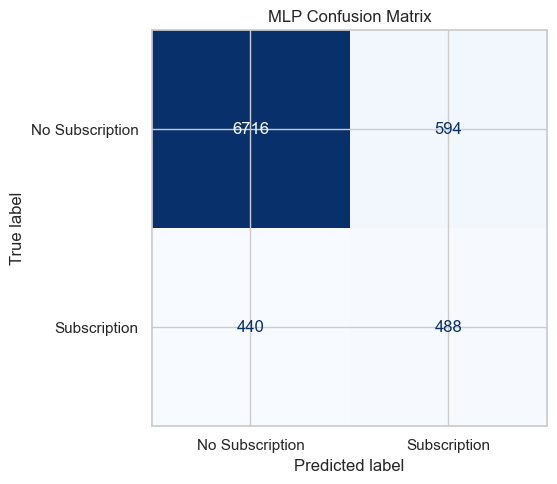

In [54]:
# BEST MODEL EVALUATION - MLP
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# GENERATE CONFUSION MATRIX
cm_mlp = confusion_matrix(
    y_test_array,
    mlp_test_predictions,
    labels=["no", "yes"]
)

# DISPLAY CONFUSION MATRIX
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=["No Subscription", "Subscription"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("MLP Confusion Matrix")
plt.tight_layout()
plt.show()

In [55]:
# DISPLAY CLASSIFICATION REPORT
print("MLP CLASSIFICATION REPORT")
print("------------------------------")

print(
    classification_report(
        y_test_array,
        mlp_test_predictions,
        labels=["no", "yes"],
        target_names=["No Subscription", "Subscription"],
        zero_division=0,
        digits=4
    )
)

# DISPLAY DECISION THRESHOLD
print("MLP Optimal Threshold:", optimal_mlp_threshold)


MLP CLASSIFICATION REPORT
------------------------------
                 precision    recall  f1-score   support

No Subscription     0.9385    0.9187    0.9285      7310
   Subscription     0.4510    0.5259    0.4856       928

       accuracy                         0.8745      8238
      macro avg     0.6948    0.7223    0.7070      8238
   weighted avg     0.8836    0.8745    0.8786      8238

MLP Optimal Threshold: 0.6950057744979858


### Best Model Evaluation Results

The selected MLP model was evaluated on the independent test dataset using the optimized classification threshold of 0.695.

The confusion matrix shows that the model correctly classified 6,716 non-subscribers and 488 actual subscribers. It also produced 594 false positives and 440 false negatives.

For the positive class (`yes`), the model achieved a precision of 0.4510, a recall of 0.5259, and an F1-score of 0.4856. This indicates that the model identified approximately 52.59% of actual subscribers, although a considerable proportion of predicted subscribers did not convert.

The model performed more strongly on the negative class, achieving a precision of 0.9385 and a recall of 0.9187. This difference reflects the challenge of identifying the minority subscription class.

From a business perspective, false negatives represent potential subscribers who may be missed by the targeting strategy, while false positives represent marketing contacts allocated to customers who ultimately do not subscribe.

Overall, the MLP provides a useful basis for customer prioritization. However, the classification threshold should be interpreted separately from the top-K ranking strategy, since the bank's operational objective is to prioritize customers within a limited outreach capacity.

### Permutation Feature Importance

Permutation Feature Importance is used to identify the contribution of individual input features to the predictive performance of the selected MLP model.

The method measures feature importance by evaluating the reduction in model performance when the values of one feature are randomly shuffled. A larger decrease in Average Precision indicates that the model relies more heavily on that feature to distinguish potential subscribers from non-subscribers.

Average Precision is selected as the scoring metric because the primary business objective is to identify the minority subscription class effectively.

The permutation process is performed on the original input features before preprocessing. This allows the importance of categorical variables to be assessed as complete features rather than as separate one-hot encoded categories.

The analysis is conducted as a post-hoc interpretation of the finalized model. Its results are used to understand model behavior and support business interpretation, not to modify the model or select features using the test set.

In [56]:

# ============================================================
# PERMUTATION FEATURE IMPORTANCE - MLP
# ============================================================

# CALCULATE BASELINE PR-AUC
baseline_probabilities = predict_mlp(
    final_mlp_model,
    to_dense_array(
        final_mlp_preprocessor.transform(X_test)
    )
)

baseline_pr_auc = average_precision_score(
    y_test_binary,
    baseline_probabilities
)

# INITIALIZE PERMUTATION CONFIGURATION
N_REPEATS = 10
rng = np.random.default_rng(RANDOM_STATE)

permutation_results = []

# CALCULATE FEATURE IMPORTANCE
for feature in X_test.columns:

    importance_scores = []

    for repeat in range(N_REPEATS):

        X_permuted = X_test.copy()

        X_permuted[feature] = rng.permutation(
            X_permuted[feature].to_numpy()
        )

        X_permuted_transformed = to_dense_array(
            final_mlp_preprocessor.transform(X_permuted)
        )

        permuted_probabilities = predict_mlp(
            final_mlp_model,
            X_permuted_transformed
        )

        permuted_pr_auc = average_precision_score(
            y_test_binary,
            permuted_probabilities
        )

        importance_scores.append(
            baseline_pr_auc - permuted_pr_auc
        )

    permutation_results.append({
        "Feature": feature,
        "Importance Mean": np.mean(importance_scores),
        "Importance Std": np.std(importance_scores, ddof=1)
    })

# CREATE RESULTS DATAFRAME
permutation_importance_df = pd.DataFrame(
    permutation_results
).sort_values(
    by="Importance Mean",
    ascending=False
).reset_index(drop=True)

print(f"Baseline Test PR-AUC: {baseline_pr_auc:.4f}")

display(
    permutation_importance_df.round(5)
)


Baseline Test PR-AUC: 0.4613


,Feature,Importance Mean,Importance Std
0,nr.employed,0.063,0.005
1,poutcome,0.028,0.003
2,month,0.026,0.003
3,contact,0.020,0.004
4,previously_contacted,0.017,0.003
5,cons.price.idx,0.012,0.004
6,emp.var.rate,0.009,0.002
7,euribor3m,0.009,0.002
8,campaign,0.008,0.004
9,day_of_week,0.007,0.003


### Permutation Feature Importance Results

The permutation feature importance analysis identified `nr.employed` as the most influential feature in the MLP model, with a mean importance of 0.063 and a standard deviation of 0.005. This indicates that randomly shuffling this feature produced the largest reduction in test Average Precision.

Other important features included `poutcome` (0.028), `month` (0.026), `contact` (0.020), and `previously_contacted` (0.017). These results highlight the predictive contribution of previous campaign outcomes, campaign timing, contact channels, and customer contact history.

Economic indicators also contributed to the model's predictive performance. In addition to `nr.employed`, `cons.price.idx`, `emp.var.rate`, and `euribor3m` showed positive importance values.

In contrast, several demographic and financial features, including `age`, `job`, `education`, `loan`, and `housing`, showed relatively small importance values. Some features, such as `cons.conf.idx`, `previous`, and `days_since_previous_contact`, produced values close to zero or slightly negative, indicating that their permutation did not reduce the model's Average Precision.

Overall, the results suggest that the MLP relies more heavily on economic conditions and campaign-related information than on individual demographic characteristics when ranking potential term deposit subscribers.

These findings should be interpreted as measures of predictive contribution rather than causal effects. Correlations among economic indicators and interactions between features may also influence the observed importance values.

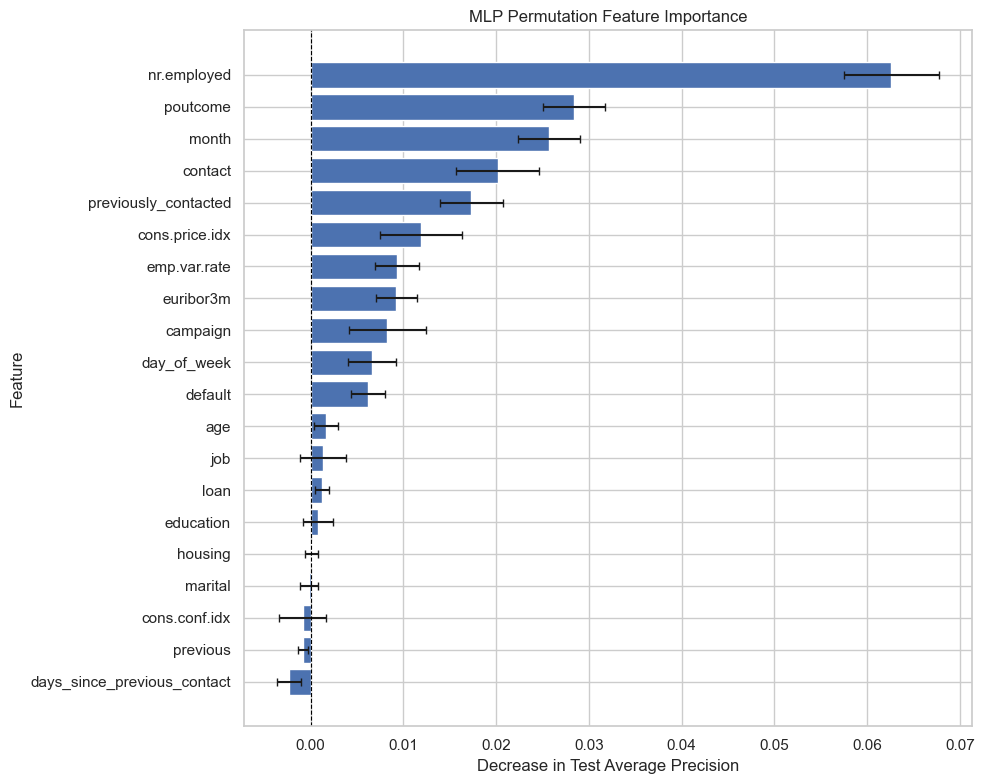

In [57]:

# ============================================================
# PERMUTATION FEATURE IMPORTANCE VISUALIZATION
# ============================================================

importance_plot_df = permutation_importance_df.sort_values(
    by="Importance Mean",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    importance_plot_df["Feature"],
    importance_plot_df["Importance Mean"],
    xerr=importance_plot_df["Importance Std"],
    capsize=3
)

plt.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=0.8
)

plt.title("MLP Permutation Feature Importance")
plt.xlabel("Decrease in Test Average Precision")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


### Permutation Feature Importance Visualization

The permutation feature importance visualization highlights the relative contribution of each input feature to the MLP model's predictive performance.

The `nr.employed` feature clearly dominates the ranking, with a mean importance of 0.063, followed by `poutcome` (0.028), `month` (0.026), `contact` (0.020), and `previously_contacted` (0.017).

The error bars represent the standard deviation across repeated permutations. The relatively consistent importance of the leading features indicates that their contribution to the model's predictive performance is not driven by a single random permutation.

The visualization further shows that several demographic and financial features have limited individual contributions to Average Precision. Some features produce importance values close to zero or slightly negative, suggesting that their individual predictive contribution is limited under the current model configuration.

From a business perspective, the findings emphasize the importance of economic indicators, previous campaign outcomes, contact history, and campaign timing in customer prioritization. These variables provide useful predictive information for identifying customers with a higher likelihood of subscribing to term deposits.

However, permutation importance measures predictive contribution rather than causality. Correlations among economic indicators and interactions between features should be considered when interpreting the results.

### SHAP Analysis

SHapley Additive exPlanations (SHAP) is used to interpret the predictions generated by the selected MLP model. It provides a framework for explaining how individual features contribute to the model output based on Shapley values from cooperative game theory.

While Permutation Feature Importance measures the reduction in predictive performance when a feature is shuffled, SHAP explains the contribution of each feature to individual predictions.

In [58]:
# SHAP DATA PREPARATION
import shap

# SET RANDOM SEED
rng = np.random.default_rng(RANDOM_STATE)

# SELECT BACKGROUND SAMPLES FROM TRAINING DATA
background_size = min(100, len(X_train_final))

background_indices = rng.choice(
    len(X_train_final),
    size=background_size,
    replace=False
)

X_shap_background = torch.tensor(
    X_train_final[background_indices],
    dtype=torch.float32,
    device=device
)

# SELECT EXPLANATION SAMPLES FROM TEST DATA
explanation_size = min(300, len(X_test_final))

explanation_indices = rng.choice(
    len(X_test_final),
    size=explanation_size,
    replace=False
)

X_shap_explain = torch.tensor(
    X_test_final[explanation_indices],
    dtype=torch.float32,
    device=device
)

# GET PREPROCESSED FEATURE NAMES
shap_feature_names = (
    final_mlp_preprocessor.get_feature_names_out()
)

# SET MODEL TO EVALUATION MODE
final_mlp_model.eval()

# DISPLAY SHAP DATA INFORMATION
print("Background Data Shape:", X_shap_background.shape)
print("Explanation Data Shape:", X_shap_explain.shape)
print("Number of Encoded Features:", len(shap_feature_names))


Background Data Shape: torch.Size([100, 63])
Explanation Data Shape: torch.Size([300, 63])
Number of Encoded Features: 63


In [59]:
# SHAP VALUE CALCULATION - MLP
shap_explainer = shap.GradientExplainer(
    final_mlp_model,
    X_shap_background
)

# CALCULATE SHAP VALUES
shap_values = shap_explainer.shap_values(
    X_shap_explain
)

# HANDLE DIFFERENT SHAP OUTPUT FORMATS
if isinstance(shap_values, list):
    shap_values = shap_values[0]

shap_values = np.asarray(shap_values)

# REMOVE SINGLE OUTPUT DIMENSION IF PRESENT
if shap_values.ndim == 3 and shap_values.shape[-1] == 1:
    shap_values = shap_values.squeeze(-1)

# CONVERT EXPLANATION DATA TO NUMPY
X_shap_explain_np = (
    X_shap_explain.detach().cpu().numpy()
)

# VALIDATE SHAP OUTPUT
print("SHAP Values Shape:", shap_values.shape)
print("Explanation Data Shape:", X_shap_explain_np.shape)
print("Feature Names:", len(shap_feature_names))

assert shap_values.shape == X_shap_explain_np.shape
assert shap_values.shape[1] == len(shap_feature_names)

print("\nSHAP values calculated successfully.")


SHAP Values Shape: (300, 63)
Explanation Data Shape: (300, 63)
Feature Names: 63

SHAP values calculated successfully.


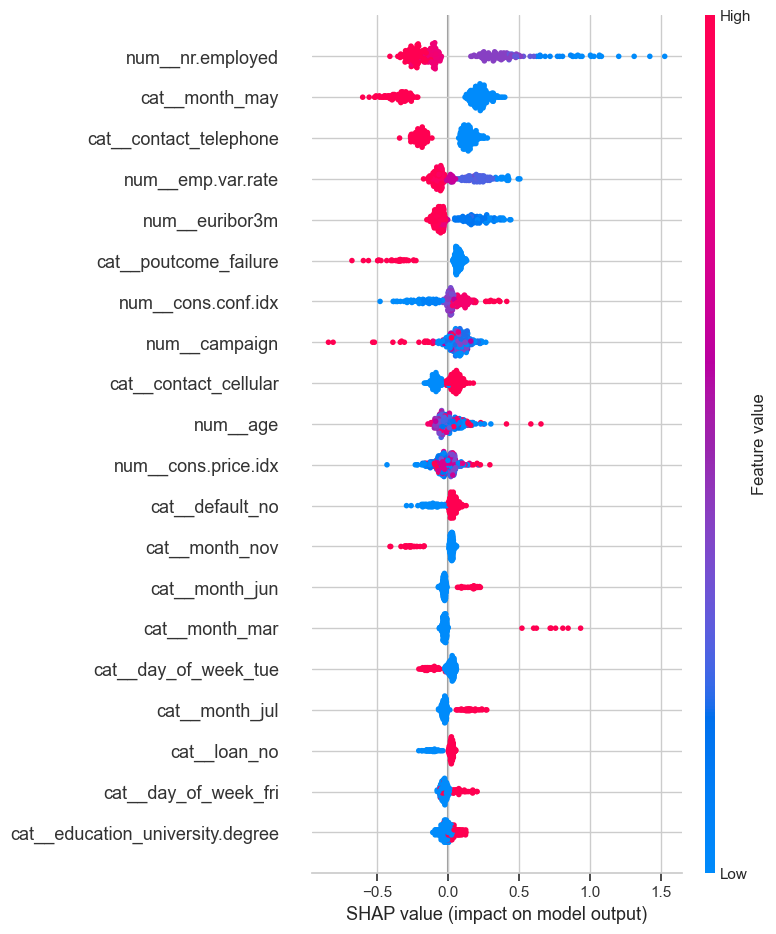

In [60]:
# GENERATE GLOBAL SHAP SUMMARY PLOT
shap.summary_plot(
    shap_values,
    X_shap_explain_np,
    feature_names=shap_feature_names,
    max_display=20,
    show=True
)


### SHAP Summary Plot Interpretation

The SHAP Summary Plot provides a global explanation of the MLP model by illustrating how individual features contribute to its predictions across 300 test observations.

The most influential feature is `nr.employed`, where higher values generally contribute negatively to the model output, while lower values tend to contribute positively. This indicates that employment-related economic conditions play an important role in the model's prediction process.

Campaign timing and communication channels also show substantial contributions. The `month` features indicate that the predicted subscription likelihood varies across campaign months. Similarly, `contact` features suggest that communication channels are relevant when prioritizing potential customers.

Economic indicators, including `emp.var.rate`, `euribor3m`, and `cons.conf.idx`, also influence model predictions. Their contributions should be interpreted carefully because these variables exhibit relatively high correlations, which may affect how predictive importance is distributed across related features.

Furthermore, `poutcome_failure` generally contributes negatively to the model output when active, indicating that a previously unsuccessful campaign outcome is associated with lower predicted subscription scores.

From a business perspective, these findings suggest that customer prioritization should consider macroeconomic conditions, campaign timing, communication channels, and previous campaign outcomes. These insights can support more informed targeting decisions under limited campaign outreach capacity.

It should be noted that SHAP values explain the model's learned patterns and do not establish causal relationships. For one-hot encoded categorical features, a feature value of zero indicates that the corresponding category is inactive, rather than identifying a specific alternative category.

In [61]:

# ============================================================
# MODEL SAVING
# ============================================================

import os
import json
import joblib
import torch

# CREATE MODEL DIRECTORY
MODEL_DIR = "models"
os.makedirs(MODEL_DIR, exist_ok=True)

# DEFINE MODEL ARTIFACT PATHS
MODEL_PATH = os.path.join(MODEL_DIR, "final_mlp_model.pth")
PREPROCESSOR_PATH = os.path.join(MODEL_DIR, "final_mlp_preprocessor.pkl")
METADATA_PATH = os.path.join(MODEL_DIR, "model_metadata.json")

# SAVE TRAINED MLP MODEL
torch.save(
    final_mlp_model.state_dict(),
    MODEL_PATH
)

# SAVE PREPROCESSING PIPELINE
joblib.dump(
    final_mlp_preprocessor,
    PREPROCESSOR_PATH
)

# SAVE MODEL METADATA
model_metadata = {
    "model_name": "PyTorch Multilayer Perceptron",
    "model_type": "MLP",
    "input_features": X_train.columns.tolist(),
    "encoded_features": shap_feature_names.tolist(),
    "prediction_threshold": float(optimal_mlp_threshold),
    "target_classes": ["no", "yes"],
    "positive_class": "yes",
    "random_state": RANDOM_STATE
}

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(
        model_metadata,
        file,
        indent=4
    )

print("MODEL ARTIFACTS SAVED SUCCESSFULLY")
print("--------------------------------------------")
print("Model:", MODEL_PATH)
print("Preprocessor:", PREPROCESSOR_PATH)
print("Metadata:", METADATA_PATH)


MODEL ARTIFACTS SAVED SUCCESSFULLY
--------------------------------------------
Model: models\final_mlp_model.pth
Preprocessor: models\final_mlp_preprocessor.pkl
Metadata: models\model_metadata.json


# IV. CONCLUSION, BUSINESS IMPACT & RECOMMENDATIONS

### Conclusion

This project developed an end-to-end machine learning and deep learning workflow to predict customer subscription to bank term deposits using the UCI Bank Marketing dataset.

Three models were developed and evaluated: Logistic Regression, Random Forest, and a PyTorch Multilayer Perceptron (MLP). The modeling process included exploratory data analysis, feature engineering, data preprocessing, model training, performance evaluation, and model interpretation.

Based on cross-validation results, MLP achieved the highest mean PR-AUC of 0.448, followed by Logistic Regression at 0.444 and Random Forest at 0.372.

On the test set, MLP achieved a PR-AUC of 0.461, an F1-score of 0.486, Precision@100 of 0.800, and Lift@100 of 7.102. Logistic Regression achieved a slightly higher ROC-AUC of 0.798, compared with 0.795 for MLP.

Considering its cross-validation PR-AUC and business-oriented ranking performance, MLP was selected as the final model. The results demonstrate its potential to support customer prioritization under limited campaign outreach capacity.

### Business Impact

The model can support bank marketing operations by ranking customers according to their predicted likelihood of subscribing to a term deposit.

The Precision@100 result of 0.800 indicates that 80 out of the 100 highest-ranked customers in the test set were actual subscribers. The Lift@100 of 7.102 indicates that this selected group had approximately 7.1 times the subscription rate of the overall test population.

These results suggest several potential business benefits:

- **Improved campaign targeting:** Marketing teams can prioritize customers with higher predicted subscription likelihood.
- **More efficient outreach allocation:** Limited calling resources can be directed toward a ranked list of potential customers.
- **Data-driven campaign planning:** Campaign month and communication channel provide useful predictive signals for planning outreach activities.
- **Better customer prioritization:** Previous campaign outcomes and economic indicators can contribute to customer ranking decisions.

The model should be treated as a decision-support tool rather than an automatic replacement for marketing decisions. Actual financial impact has not yet been measured through a live campaign experiment.

### Business Recommendations

Based on the evaluation and model interpretation results, the following recommendations are proposed:

**Customer Prioritization**

Use the MLP prediction scores to rank customers and select the highest-priority prospects according to the available outreach capacity. The top 100 ranking was used as the evaluation scenario in this project.

**Campaign Planning**

Consider campaign timing and communication channel when designing outreach strategies. The SHAP analysis indicates that month and contact method contribute meaningfully to model predictions.

**Economic Context Monitoring**

Monitor economic indicators such as `nr.employed`, `emp.var.rate`, and `euribor3m`. These variables are among the influential predictors identified during model interpretation.

**Threshold and Capacity Management**

Do not treat the classification threshold as interchangeable with the top-K ranking strategy. The threshold of approximately 0.695 was used for binary classification evaluation, while Precision@100 and Lift@100 assess the ranking of the top 100 customers.

The operational threshold or outreach capacity should be selected according to campaign resources, business costs, and expected returns.

**Continuous Model Evaluation**

Evaluate model performance periodically using PR-AUC, Precision@K, Recall@K, and Lift@K. Reassess the model when customer behavior, campaign strategy, or economic conditions change.

### Final Recommendation

The PyTorch MLP is recommended as the primary model for customer subscription prioritization in this project. Logistic Regression should be retained as a competitive baseline because of its comparable PR-AUC and slightly higher test ROC-AUC.

Before operational deployment, the model should undergo temporal validation, business cost analysis, and a controlled campaign experiment to verify whether model-assisted targeting improves actual subscription outcomes.

# V. LIMITATIONS & NEXT STEPS

### Dataset Limitations

The dataset represents historical bank marketing campaigns and may not fully reflect current customer behavior, market conditions, or banking strategies.

The target variable is imbalanced, with approximately 88.74% of observations belonging to the `no` class and 11.26% belonging to the `yes` class. Although imbalance-aware evaluation metrics were used, the model may still have limitations when identifying less frequent subscription cases.

Some categorical features also contain `unknown` values. These observations were retained during preprocessing, but their underlying information remains uncertain.

### Feature Limitations

The `duration` feature was excluded because it is only available after a customer interaction has taken place. This decision prevents data leakage in the intended pre-call prediction scenario, but also limits the information available to the model.

Several economic indicators exhibit strong correlations, particularly `emp.var.rate`, `euribor3m`, and `nr.employed`. These relationships may affect the distribution and interpretation of feature importance.

Additionally, the dataset does not provide all information that may influence a customer's subscription decision, such as detailed customer financial profiles, individual preferences, or current product suitability.

### Model Limitations

Although MLP achieved the highest cross-validation PR-AUC among the evaluated models, its performance advantage over Logistic Regression was relatively small.

Random Forest showed a substantial difference between training and cross-validation performance, suggesting potential overfitting.

The selected MLP configuration was evaluated using predefined model configurations rather than an extensive hyperparameter optimization process. Therefore, other architectures or configurations may achieve different results.

### Evaluation Limitations

The evaluation was performed using a stratified train-test split rather than a temporal validation strategy. Consequently, the test results do not fully measure how the model would perform when predicting subscriptions in a future campaign period.

Precision@100 and Lift@100 were calculated using a fixed capacity of 100 customers. Actual campaign capacity may vary depending on the available marketing budget, personnel, and operational constraints.

The prediction threshold of approximately 0.695 was used for binary classification evaluation. Its suitability for real campaign operations has not yet been established through financial cost-benefit analysis.

### Explainability Limitations

Permutation Feature Importance was calculated using the original input features, while SHAP analysis was performed on the encoded feature representation containing 63 features.

Therefore, their feature rankings are not directly equivalent. One-hot encoded categorical features may need to be grouped to obtain a more consolidated interpretation at the original feature level.

SHAP explanations were generated using a sample of 300 test observations and a background sample of 100 training observations. These explanations may not represent every possible customer profile.

Both PFI and SHAP describe model behavior and predictive relationships. They do not establish causal relationships between customer characteristics and subscription decisions.

### Next Steps

Several improvements are recommended for future development:

- **Temporal Validation:** Use time-based training and testing splits to evaluate the model's ability to generalize to future campaigns.
- **Business Cost Analysis:** Incorporate outreach costs, campaign capacity, and the expected value of successful subscriptions when determining operational thresholds.
- **Ranking Optimization:** Evaluate different outreach capacities using Precision@K, Recall@K, and Lift@K.
- **Model Comparison:** Further investigate the performance differences between MLP and Logistic Regression under consistent validation conditions.
- **Feature Interpretation:** Aggregate SHAP values across one-hot encoded categories to improve business-level interpretability.
- **Model Monitoring:** Monitor prediction performance, input data distributions, and changes in customer behavior after deployment.
- **Campaign Experimentation:** Conduct controlled experiments to determine whether model-assisted targeting improves actual subscription outcomes.

### Final Remarks

This project establishes a reproducible foundation for predicting bank term deposit subscriptions using machine learning and deep learning techniques.

The selected MLP model demonstrates promising performance for customer ranking and campaign prioritization. However, further temporal validation, business evaluation, and operational monitoring are necessary before the model can be considered ready for real-world deployment.